# Valuing Any Used Car in 2026 — Leak-Free GridSearchCV & Hybrid Depreciation Pipeline

Run end-to-end in Google Colab (**Runtime → Run all**) or locally. Zero manual uploads needed.

## What this notebook builds
1. **38-brand, 345-model Catalogue** with word-boundary matching (`Kia Clavis` ≠ `Mercedes CLA`) and brand-sibling fallback.
2. **2026-Calibrated Depreciation Curve** (`RETENTION_LEVEL = 1.36`) with smooth `tanh` odometer sensitivity.
3. **Training-Set Correlation Matrix & Iterative Feature Reduction (`12 → 9`)** computed strictly on `X_train` (`n=5,548`) with untouched `X_test` (`n=1,387`).
4. **Leak-Free `Pipeline` + 5-Fold `GridSearchCV`** comparing **SVM (`SVR`)**, **Random Forest**, and **KNN** — selecting **`SVR (kernel='rbf', C=10, gamma='auto', log1p y)`** at **84.45% 5-Fold CV R²** and **91.14% Untouched Test R²** (`Test MAE = ₹84,283`, `Test MAPE = 16.3%`).

## 0. Setup

In [1]:
import sys, warnings, textwrap
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

LAKH = 1e5
VALUATION_YEAR = 2026

print("python  ", sys.version.split()[0])
print("numpy   ", np.__version__)
print("pandas  ", pd.__version__)
print("sklearn ", sklearn.__version__)

python   3.13.14
numpy    2.5.4
pandas   3.1.1
sklearn  1.9.1


## 1. Structured Car Catalogue (38 Brands, 345 Models)

In [2]:
# ==========================================================================
# CATALOGUE
# --------------------------------------------------------------------------
# Verbatim from src/carprice/catalogue.py in the project repo.
# ==========================================================================
#
# 38 brands, ~340 models, brand aliases, and the word-boundary model matcher.

from dataclasses import dataclass

#: segment -> short human label used in the UI
SEGMENT_LABELS = {
    "hatchback": "Hatchback",
    "sedan": "Sedan",
    "suv": "SUV",
    "mpv": "MPV / 7-seater",
    "luxury-hatch": "Luxury hatchback",
    "luxury-sedan": "Luxury sedan",
    "luxury-suv": "Luxury SUV",
    "ev-hatch": "Electric hatchback",
    "ev-sedan": "Electric sedan",
    "ev-suv": "Electric SUV",
    "pickup": "Pickup / utility",
}


@dataclass(frozen=True)
class ModelSpec:
    segment: str
    ex_showroom_lakh: float
    engine_cc: int
    seats: int


def _m(segment: str, price: float, cc: int, seats: int = 5) -> ModelSpec:
    return ModelSpec(segment, price, cc, seats)


# --------------------------------------------------------------------------- #
# The catalogue.
#
# Keyed by brand, then by the canonical model name. Order within a brand does not
# matter; matching is longest-name-first so "Grand i10" wins over "i10",
# "Innova Crysta" over "Innova", "Swift Dzire" over "Swift".
# --------------------------------------------------------------------------- #
CATALOGUE: dict[str, dict[str, ModelSpec]] = {
    "Maruti Suzuki": {
        "Alto 800":        _m("hatchback", 3.30, 796),
        "Alto K10":        _m("hatchback", 4.00, 998),
        "S-Presso":        _m("hatchback", 4.30, 998),
        "Celerio":         _m("hatchback", 5.40, 998),
        "Wagon R":         _m("hatchback", 5.80, 998),
        "Swift Dzire":     _m("sedan", 7.00, 1197),
        "Swift":           _m("hatchback", 6.60, 1197),
        "Dzire":           _m("sedan", 7.00, 1197),
        "Ignis":           _m("hatchback", 6.30, 1197),
        "Baleno":          _m("hatchback", 7.20, 1197),
        "Fronx":           _m("suv", 7.60, 1197),
        "Taisor":          _m("suv", 8.00, 1197),
        "Brezza":          _m("suv", 9.00, 1462),
        "Ertiga":          _m("mpv", 9.00, 1462, 7),
        "XL6":             _m("mpv", 12.20, 1462, 6),
        "Grand Vitara":    _m("suv", 11.50, 1462),
        "Jimny":           _m("suv", 12.70, 1462, 4),
        "Invicto":         _m("mpv", 25.20, 1987, 7),
        "eVitara":         _m("ev-suv", 17.50, 0),
        "Ciaz":            _m("sedan", 9.50, 1462),
        "Omni":            _m("mpv", 3.20, 796, 5),
        "Eeco":            _m("mpv", 5.60, 1197, 5),
        "Ritz":            _m("hatchback", 5.00, 1197),
        "SX4":             _m("sedan", 7.50, 1586),
    },
    "Hyundai": {
        "Grand i10 Nios":  _m("hatchback", 6.00, 1197),
        "Grand i10":       _m("hatchback", 6.00, 1197),
        "i10":             _m("hatchback", 5.50, 1086),
        "Santro":          _m("hatchback", 5.00, 1086),
        "Eon":             _m("hatchback", 4.20, 814),
        "Exter":           _m("suv", 6.20, 1086),
        "i20":             _m("hatchback", 7.50, 1197),
        "Aura":            _m("sedan", 6.50, 1197),
        "Xcent":           _m("sedan", 6.00, 1197),
        "Venue":           _m("suv", 8.00, 1197),
        "Verna":           _m("sedan", 11.00, 1497),
        "Creta":           _m("suv", 11.20, 1497),
        "Alcazar":         _m("suv", 14.99, 1497, 6),
        "Creta N Line":    _m("suv", 13.50, 1353),
        "Ioniq 5":         _m("ev-suv", 46.00, 0),
        "Kona Electric":   _m("ev-suv", 24.00, 0),
        "Elantra":         _m("sedan", 16.00, 1999),
        "Tucson":          _m("suv", 30.00, 1997),
    },
    "Tata": {
        "Tiago":           _m("hatchback", 5.70, 1199),
        "Tigor":           _m("sedan", 6.30, 1199),
        "Punch":           _m("suv", 6.20, 1199),
        "Altroz":          _m("hatchback", 7.00, 1199),
        "Nexon":           _m("suv", 8.00, 1199),
        "Curvv":           _m("suv", 10.00, 1199),
        "Sierra":          _m("suv", 11.50, 1199),
        "Harrier":         _m("suv", 15.50, 1956),
        "Safari":          _m("suv", 16.50, 1956, 6),
        "Indica":          _m("hatchback", 4.00, 1193),
        "Indica Vista":    _m("hatchback", 4.50, 1193),
        "Indigo":          _m("sedan", 5.00, 1193),
        "Indigo CS":       _m("sedan", 5.00, 1193),
        "Zest":            _m("sedan", 5.80, 1193),
        "Manza":           _m("sedan", 5.50, 1248),
        "Bolt":            _m("hatchback", 5.20, 1193),
        "Nano":            _m("hatchback", 2.60, 624),
        "Sumo":            _m("suv", 5.50, 1948, 7),
        "Xenon":           _m("pickup", 7.00, 2179),
        "Nexon EV":        _m("ev-suv", 14.50, 0),
        "Tiago EV":        _m("ev-hatch", 8.00, 0),
        "Tigor EV":        _m("ev-sedan", 8.50, 0),
        "Punch EV":        _m("ev-suv", 9.50, 0),
        "Curvv EV":        _m("ev-suv", 17.00, 0),
        "Harrier EV":      _m("ev-suv", 21.00, 0),
        "Safari EV":       _m("ev-suv", 22.00, 0, 6),
        "Avinya":          _m("ev-suv", 20.00, 0),
    },
    "Mahindra": {
        "Bolero":          _m("suv", 9.50, 2523, 7),
        "Bolero Neo":      _m("suv", 9.20, 2184, 7),
        "Bolero Power Plus": _m("suv", 8.50, 1493, 7),
        "KUV 100":         _m("suv", 5.50, 1198),
        "TUV 300":         _m("suv", 7.50, 1493, 7),
        "XUV 300":         _m("suv", 8.00, 1197),
        "XUV 3XO":         _m("suv", 8.00, 1197),
        "XUV 500":         _m("suv", 13.00, 2179, 7),
        "XUV 700":         _m("suv", 14.50, 1997, 7),
        "Scorpio":         _m("suv", 13.60, 2184, 7),
        "Scorpio N":       _m("suv", 13.60, 1997, 7),
        "Scorpio Classic": _m("suv", 13.60, 2184, 7),
        "Thar":            _m("suv", 11.50, 1997, 4),
        "Thar Roxx":       _m("suv", 12.99, 1997, 5),
        "Xylo":            _m("mpv", 8.50, 2489, 7),
        "Marazzo":         _m("mpv", 13.00, 1497, 7),
        "Quanto":          _m("suv", 6.00, 1493, 7),
        "TUV":             _m("suv", 7.50, 1493, 7),
        "Alturas G4":      _m("luxury-suv", 30.00, 2147, 7),
        "XEV 9e":          _m("ev-suv", 21.90, 0),
        "BE 6":            _m("ev-suv", 18.90, 0),
        "XUV400":          _m("ev-suv", 15.50, 0),
        "Verito":          _m("sedan", 6.00, 1461),
        "Logan":           _m("sedan", 5.50, 1461),
    },
    "Honda": {
        "Brio":            _m("hatchback", 5.00, 1198),
        "Jazz":            _m("hatchback", 7.50, 1199),
        "Amaze":           _m("sedan", 7.50, 1199),
        "City":            _m("sedan", 12.00, 1498),
        "City Hybrid":     _m("sedan", 19.00, 1498),
        "Verna":           _m("sedan", 11.00, 1497),
        "Civic":           _m("luxury-sedan", 22.00, 1799),
        "Accord":          _m("luxury-sedan", 40.00, 1993),
        "WR-V":            _m("suv", 9.00, 1199),
        "Elevate":         _m("suv", 11.70, 1498),
        "BR-V":            _m("mpv", 10.00, 1498, 7),
        "Mobilio":         _m("mpv", 7.50, 1498, 7),
        "CR-V":            _m("luxury-suv", 30.00, 1997),
        "HR-V":            _m("suv", 15.00, 1498),
    },
    "Toyota": {
        "Etios":           _m("sedan", 6.50, 1364),
        "Etios Liva":      _m("hatchback", 6.00, 1197),
        "Etios Cross":     _m("hatchback", 6.50, 1364),
        "Liva":            _m("hatchback", 6.00, 1197),
        "Glanza":          _m("hatchback", 7.00, 1197),
        "Taisor":          _m("suv", 8.00, 1197),
        "Urban Cruiser":   _m("suv", 9.00, 1462),
        "Urban Cruiser Hyryder": _m("suv", 11.50, 1462),
        "Rumion":          _m("mpv", 10.50, 1462, 7),
        "Innova":          _m("mpv", 19.00, 2393, 7),
        "Innova Crysta":   _m("mpv", 19.50, 2393, 7),
        "Innova Hycross":  _m("mpv", 19.00, 1987, 7),
        "Corolla":         _m("sedan", 17.00, 1598),
        "Corolla Altis":   _m("sedan", 17.00, 1598),
        "Yaris":           _m("sedan", 9.50, 1496),
        "Camry":           _m("luxury-sedan", 48.00, 2487),
        "Fortuner":        _m("suv", 33.00, 2755, 7),
        "Fortuner Legender": _m("suv", 36.00, 2755, 7),
        "Qualis":          _m("mpv", 7.00, 2446, 7),
        "Hilux":           _m("pickup", 30.00, 2755),
        "Vellfire":        _m("luxury-suv", 95.00, 2487, 7),
        "Land Cruiser":    _m("luxury-suv", 210.00, 3346, 7),
    },
    "Kia": {
        "Sonet":           _m("suv", 8.00, 1197),
        "Syros":           _m("suv", 9.00, 1197),
        "Seltos":          _m("suv", 11.00, 1497),
        "Carens":          _m("mpv", 11.00, 1497, 7),
        "Carnival":        _m("mpv", 32.00, 2199, 7),
        "EV6":             _m("ev-suv", 66.00, 0),
        "EV9":             _m("ev-suv", 130.00, 0, 7),
        "Carens Clavis":   _m("mpv", 11.50, 1497, 7),
    },
    "Renault": {
        "Kwid":            _m("hatchback", 4.70, 999),
        "Triber":          _m("mpv", 6.00, 999, 7),
        "Kiger":           _m("suv", 6.00, 999),
        "Duster":          _m("suv", 9.00, 1498),
        "Lodgy":           _m("mpv", 8.50, 1461, 7),
        "Pulse":           _m("hatchback", 5.00, 1198),
        "Scala":           _m("sedan", 7.00, 1498),
        "Captur":          _m("suv", 11.00, 1498),
        "Fluence":         _m("sedan", 14.00, 1598),
    },
    "Nissan": {
        "Micra":           _m("hatchback", 6.00, 1198),
        "Sunny":           _m("sedan", 7.00, 1498),
        "Terrano":         _m("suv", 10.00, 1461),
        "Kicks":           _m("suv", 10.00, 1498),
        "Magnite":         _m("suv", 6.00, 999),
        "Tekna":           _m("suv", 7.00, 999),
        "X-Trail":         _m("luxury-suv", 50.00, 2498),
        "GTR":             _m("luxury-suv", 220.00, 3799),
    },
    "Volkswagen": {
        "Polo":            _m("hatchback", 8.00, 999),
        "Ameo":            _m("sedan", 6.50, 1197),
        "Vento":           _m("sedan", 10.00, 999),
        "Virtus":          _m("sedan", 11.50, 999),
        "Taigun":          _m("suv", 11.50, 999),
        "Tiguan":          _m("luxury-suv", 35.00, 1984),
        "T-Roc":           _m("suv", 21.00, 1498),
        "Jetta":           _m("luxury-sedan", 20.00, 1395),
        "Passat":          _m("luxury-sedan", 30.00, 1984),
        "Touareg":         _m("luxury-suv", 75.00, 2967),
        "Touran":          _m("mpv", 20.00, 1598, 7),
    },
    "Skoda": {
        "Fabia":           _m("hatchback", 6.50, 1197),
        "Rapid":           _m("sedan", 9.00, 999),
        "Slavia":          _m("sedan", 11.00, 999),
        "Laura":           _m("luxury-sedan", 17.00, 1896),
        "Octavia":         _m("luxury-sedan", 28.00, 1984),
        "Superb":          _m("luxury-sedan", 40.00, 1984),
        "Kushaq":          _m("suv", 11.00, 999),
        "Kylaq":           _m("suv", 8.00, 999),
        "Karoq":           _m("luxury-suv", 28.00, 1498),
        "Kodiaq":          _m("luxury-suv", 40.00, 1984, 7),
        "Yeti":            _m("suv", 18.00, 1968),
    },
    "Ford": {
        "Figo":            _m("hatchback", 6.00, 1194),
        "Figo Aspire":     _m("sedan", 7.00, 1194),
        "Freestyle":       _m("hatchback", 7.00, 1194),
        "Fiesta":          _m("sedan", 8.50, 1499),
        "Fiesta Classic":  _m("sedan", 7.00, 1399),
        "Ikon":            _m("sedan", 5.50, 1396),
        "EcoSport":        _m("suv", 9.00, 1496),
        "Endeavour":       _m("luxury-suv", 33.00, 2198, 7),
        "Mustang":         _m("luxury-suv", 80.00, 5038, 4),
    },
    "Chevrolet": {
        "Spark":           _m("hatchback", 4.00, 995),
        "Beat":            _m("hatchback", 5.00, 1199),
        "Sail":            _m("sedan", 6.00, 1199),
        "Sail Hatchback":  _m("hatchback", 5.50, 1199),
        "Aveo":            _m("sedan", 6.00, 1150),
        "Cruze":           _m("luxury-sedan", 15.00, 1998),
        "Optra":           _m("sedan", 8.00, 1598),
        "Tavera":          _m("mpv", 7.00, 2499, 7),
        "Enjoy":           _m("mpv", 6.50, 1248, 7),
        "Captiva":         _m("luxury-suv", 22.00, 2231, 7),
        "Trailblazer":     _m("luxury-suv", 27.00, 2776, 7),
    },
    "Fiat": {
        "Punto":           _m("hatchback", 5.50, 1172),
        "Punto Evo":       _m("hatchback", 6.00, 1248),
        "Linea":           _m("sedan", 7.00, 1248),
        "Palio":           _m("hatchback", 4.50, 1172),
        "Avventura":       _m("hatchback", 6.50, 1248),
        "Urban Cross":     _m("hatchback", 7.00, 1248),
    },
    "Datsun": {
        "GO":              _m("hatchback", 4.00, 1198),
        "GO Plus":         _m("mpv", 4.50, 1198, 7),
        "Redi-GO":         _m("hatchback", 3.00, 799),
    },
    "MG": {
        "Hector":          _m("suv", 15.00, 1451),
        "Hector Plus":     _m("suv", 17.50, 1451, 6),
        "Astor":           _m("suv", 10.00, 1498),
        "ZS EV":           _m("ev-suv", 18.50, 0),
        "Comet EV":        _m("ev-hatch", 7.00, 0, 4),
        "Windsor EV":      _m("ev-suv", 14.00, 0),
        "Gloster":         _m("luxury-suv", 40.00, 1996, 7),
        "Cyberster":       _m("luxury-suv", 65.00, 0, 2),
        "MGS5":            _m("ev-suv", 25.00, 0),
    },
    "Jeep": {
        "Compass":         _m("suv", 20.00, 1956),
        "Meridian":        _m("suv", 25.00, 1956, 7),
        "Wrangler":        _m("luxury-suv", 70.00, 1995, 4),
        "Grand Cherokee":  _m("luxury-suv", 80.00, 2987, 5),
    },
    "BMW": {
        "1 Series":        _m("luxury-hatch", 45.00, 1998),
        "2 Series":        _m("luxury-sedan", 45.00, 1998),
        "3 Series":        _m("luxury-sedan", 60.00, 1998),
        "3 Series Gran Limousine": _m("luxury-sedan", 63.00, 1998),
        "5 Series":        _m("luxury-sedan", 75.00, 1998),
        "6 Series":        _m("luxury-sedan", 75.00, 2998),
        "7 Series":        _m("luxury-sedan", 180.00, 2998),
        "X1":              _m("luxury-suv", 50.00, 1499),
        "X2":              _m("luxury-suv", 55.00, 1998),
        "X3":              _m("luxury-suv", 75.00, 1998),
        "X4":              _m("luxury-suv", 80.00, 1998),
        "X5":              _m("luxury-suv", 100.00, 2998),
        "X6":              _m("luxury-suv", 110.00, 2998),
        "X7":              _m("luxury-suv", 130.00, 2998, 7),
        "i3":              _m("ev-sedan", 60.00, 0),
        "i4":              _m("ev-sedan", 75.00, 0),
        "iX":              _m("ev-suv", 130.00, 0),
        "Z4":              _m("luxury-sedan", 90.00, 1998, 2),
    },
    "Mercedes-Benz": {
        "A-Class":         _m("luxury-hatch", 45.00, 1332),
        "B-Class":         _m("luxury-hatch", 50.00, 1595),
        "C-Class":         _m("luxury-sedan", 60.00, 1496),
        "E-Class":         _m("luxury-sedan", 85.00, 1993),
        "S-Class":         _m("luxury-sedan", 180.00, 2999),
        "CLA":             _m("luxury-sedan", 50.00, 1332),
        "GLA":             _m("luxury-suv", 55.00, 1332),
        "GLB":             _m("luxury-suv", 65.00, 1332, 7),
        "GLC":             _m("luxury-suv", 80.00, 1993),
        "GLE":             _m("luxury-suv", 100.00, 2999),
        "GLS":             _m("luxury-suv", 130.00, 2999, 7),
        "G-Class":         _m("luxury-suv", 200.00, 2925),
        "M-Class":         _m("luxury-suv", 60.00, 2987),
        "EQS":             _m("ev-sedan", 160.00, 0),
        "EQE":             _m("ev-sedan", 130.00, 0),
        "EQB":             _m("ev-suv", 80.00, 0),
        "EQA":             _m("ev-suv", 66.00, 0),
        "V-Class":         _m("luxury-suv", 100.00, 1950, 7),
    },
    "Audi": {
        "A3":              _m("luxury-sedan", 45.00, 1395),
        "A4":              _m("luxury-sedan", 55.00, 1984),
        "A6":              _m("luxury-sedan", 70.00, 1984),
        "A8":              _m("luxury-sedan", 150.00, 2995),
        "Q3":              _m("luxury-suv", 50.00, 1395),
        "Q5":              _m("luxury-suv", 70.00, 1984),
        "Q7":              _m("luxury-suv", 90.00, 2967, 7),
        "Q8":              _m("luxury-suv", 120.00, 2995),
        "e-tron":          _m("ev-suv", 120.00, 0),
        "e-tron GT":       _m("ev-sedan", 180.00, 0),
        "TT":              _m("luxury-sedan", 70.00, 1984, 4),
    },
    "Jaguar": {
        "XE":              _m("luxury-sedan", 45.00, 1999),
        "XF":              _m("luxury-sedan", 60.00, 1999),
        "XJ":              _m("luxury-sedan", 100.00, 2993),
        "F-Pace":          _m("luxury-suv", 75.00, 1997),
        "E-Pace":          _m("luxury-suv", 60.00, 1997),
        "I-Pace":          _m("ev-suv", 110.00, 0),
        "F-Type":          _m("luxury-sedan", 110.00, 2995, 2),
    },
    "Volvo": {
        "S60":             _m("luxury-sedan", 50.00, 1969),
        "S90":             _m("luxury-sedan", 70.00, 1969),
        "V40":             _m("luxury-hatch", 30.00, 1969),
        "V60":             _m("luxury-sedan", 55.00, 1969),
        "XC40":            _m("luxury-suv", 50.00, 1969),
        "XC60":            _m("luxury-suv", 70.00, 1969),
        "XC90":            _m("luxury-suv", 100.00, 1969, 7),
        "C40":             _m("ev-suv", 60.00, 0),
        "EX30":            _m("ev-suv", 45.00, 0),
        "EX40":            _m("ev-suv", 55.00, 0),
    },
    "Land Rover": {
        "Defender":        _m("luxury-suv", 100.00, 1997, 5),
        "Discovery":       _m("luxury-suv", 80.00, 1997, 7),
        "Discovery Sport": _m("luxury-suv", 70.00, 1997, 7),
        "Range Rover Evoque": _m("luxury-suv", 70.00, 1997),
        "Range Rover Velar": _m("luxury-suv", 90.00, 1997),
        "Range Rover Sport": _m("luxury-suv", 140.00, 2996),
        "Range Rover":     _m("luxury-suv", 250.00, 2996),
    },
    "Lexus": {
        "ES":              _m("luxury-sedan", 65.00, 2487),
        "LS":              _m("luxury-sedan", 180.00, 3456),
        "NX":              _m("luxury-suv", 70.00, 2487),
        "RX":              _m("luxury-suv", 95.00, 2393),
        "LX":              _m("luxury-suv", 250.00, 3445, 7),
        "UX":              _m("luxury-suv", 45.00, 1987),
    },
    "MINI": {
        "Cooper":          _m("luxury-hatch", 45.00, 1499),
        "Countryman":      _m("luxury-suv", 50.00, 1499),
        "Clubman":         _m("luxury-hatch", 45.00, 1499),
    },
    "Porsche": {
        "Macan":           _m("luxury-suv", 90.00, 1984),
        "Cayenne":         _m("luxury-suv", 140.00, 2995),
        "911":             _m("luxury-sedan", 200.00, 2981, 2),
        "Panamera":        _m("luxury-sedan", 180.00, 2894),
        "Taycan":          _m("ev-sedan", 160.00, 0),
        "718":             _m("luxury-sedan", 100.00, 1988, 2),
    },
    "Citroen": {
        "C3":              _m("hatchback", 6.50, 1199),
        "eC3":             _m("ev-hatch", 12.00, 0),
        "C3 Aircross":     _m("suv", 11.00, 1199, 7),
        "C5 Aircross":     _m("luxury-suv", 35.00, 1499),
        "Basalt":          _m("suv", 8.00, 1199),
    },
    "BYD": {
        "Atto 3":          _m("ev-suv", 25.00, 0),
        "e6":              _m("ev-suv", 30.00, 0),
        "Seal":            _m("ev-sedan", 41.00, 0),
        "Sealion 7":       _m("ev-suv", 48.00, 0),
        "M9":              _m("ev-suv", 90.00, 0, 7),
    },
    "Isuzu": {
        "D-Max":           _m("pickup", 20.00, 1898),
        "MU-X":            _m("luxury-suv", 35.00, 1898, 7),
        "S-Cab":           _m("pickup", 15.00, 2499),
    },
    "Force Motors": {
        "Gurkha":          _m("suv", 16.00, 2596),
        "Trax":            _m("suv", 8.00, 2596, 7),
    },
    "Mitsubishi": {
        "Pajero":          _m("luxury-suv", 30.00, 2835, 7),
        "Lancer":          _m("sedan", 9.00, 1468),
        "Outlander":       _m("luxury-suv", 25.00, 2360, 7),
    },
    "Hindustan Motors": {
        "Ambassador":      _m("sedan", 5.00, 1489),
        "Contessa":        _m("sedan", 5.00, 1489),
    },
    "Daewoo": {
        "Matiz":           _m("hatchback", 3.00, 796),
        "Nexia":           _m("sedan", 4.50, 1498),
    },
    "Opel": {
        "Astra":           _m("sedan", 6.00, 1598),
        "Corsa":           _m("hatchback", 5.00, 1389),
        "Sail":            _m("sedan", 5.50, 1398),
    },
    "Peugeot": {
        "309":             _m("sedan", 4.00, 1580),
        "206":             _m("hatchback", 4.50, 1360),
    },
    "Ashok Leyland": {
        "Stile":           _m("mpv", 5.50, 1461, 7),
        "Dost":            _m("pickup", 6.00, 1478),
    },
    "Premier": {
        "Rl":              _m("hatchback", 4.50, 1173),
        "Rio":             _m("hatchback", 5.00, 1173),
    },
}

#: Brand aliases seen in listings -> catalogue key
BRAND_ALIASES = {
    "maruti": "Maruti Suzuki",
    "maruti suzuki": "Maruti Suzuki",
    "marutisuzuki": "Maruti Suzuki",
    "hyundai": "Hyundai",
    "tata": "Tata",
    "tatamotors": "Tata",
    "mahindra": "Mahindra",
    "honda": "Honda",
    "toyota": "Toyota",
    "kia": "Kia",
    "renault": "Renault",
    "nissan": "Nissan",
    "volkswagen": "Volkswagen",
    "vw": "Volkswagen",
    "skoda": "Skoda",
    "ford": "Ford",
    "chevrolet": "Chevrolet",
    "chevy": "Chevrolet",
    "fiat": "Fiat",
    "datsun": "Datsun",
    "mg": "MG",
    "jeep": "Jeep",
    "bmw": "BMW",
    "mercedes": "Mercedes-Benz",
    "mercedes-benz": "Mercedes-Benz",
    "mercedesbenz": "Mercedes-Benz",
    "audi": "Audi",
    "jaguar": "Jaguar",
    "volvo": "Volvo",
    "land rover": "Land Rover",
    "landrover": "Land Rover",
    "lexus": "Lexus",
    "mini": "MINI",
    "porsche": "Porsche",
    "citroen": "Citroen",
    "byd": "BYD",
    "isuzu": "Isuzu",
    "force": "Force Motors",
    "force motors": "Force Motors",
    "mitsubishi": "Mitsubishi",
    "ambassador": "Hindustan Motors",
    "hindustan": "Hindustan Motors",
    "daewoo": "Daewoo",
    "opel": "Opel",
    "peugeot": "Peugeot",
    "ashok leyland": "Ashok Leyland",
    "premier": "Premier",
    "tesla": "Tesla",
    "tesla motors": "Tesla",
}

#: Brands we know of but have no catalogue yet — valued on segment + age alone
UNCATALOGUED_BRANDS = {
    # Tesla entered India in 2026 with imported CBUs; Model Y RWD lands ~Rs 55 lakh
    "Tesla": {"Model 3": _m("ev-sedan", 55.00, 0),
              "Model Y": _m("ev-suv", 56.00, 0),
              "Model S": _m("ev-sedan", 110.00, 0),
              "Model X": _m("ev-suv", 120.00, 0)},
}

CATALOGUE.update(UNCATALOGUED_BRANDS)


def resolve_brand(raw: str) -> str | None:
    """Map a raw brand string ('maruti', 'Mercedes-Benz', 'MARUTI SUZUKI') to a key."""
    if raw is None:
        return None
    text = " ".join(str(raw).strip().lower().split())
    if text in BRAND_ALIASES:
        return BRAND_ALIASES[text]
    # first token fallback: 'Maruti Suzuki Swift' -> 'maruti' -> Maruti Suzuki
    first = text.split()[0] if text.split() else ""
    return BRAND_ALIASES.get(first)


def _name_pattern(option: str) -> "re.Pattern[str]":
    """
    Word-boundary pattern for a catalogue name, tolerant of the punctuation listings use.

    Matching on boundaries is not optional: a naive substring test maps 'Kia Clavis'
    onto the Mercedes 'CLA' (because "cla" sits inside "clavis") and values a ₹9 lakh
    hatchback at ₹42 lakh.
    """
    import re
    tokens = re.split(r"[\s\-]+", option.lower().strip())
    # each separator between tokens may appear as a space, a hyphen, or nothing at all,
    # so 'XUV 500' matches 'XUV500', 'Redi-Go' matches 'Redi Go', 'S-Presso' matches 'S Presso'
    body = r"[\s\-]*".join(re.escape(t) for t in tokens if t)
    return re.compile(rf"(?<![a-z0-9]){body}(?![a-z0-9])")


_PATTERN_CACHE: dict[str, "re.Pattern[str]"] = {}


def _longest_match(text: str, options: list[str], *, allow_lead: bool = False) -> str | None:
    """
    Longest catalogue name that occurs in `text` on word boundaries.

    `allow_lead` additionally accepts a match on the first token, which is how a bare
    model entry should behave: the user typing 'Clavis' means Kia's new SUV, not
    'Carens Clavis' (a different car), and 'Creta' should find 'Creta N Line'.
    """
    low = " ".join(str(text).lower().split())
    hits: list[tuple[int, str]] = []

    def _pattern(option: str):
        pat = _PATTERN_CACHE.get(option)
        if pat is None:
            pat = _name_pattern(option)
            _PATTERN_CACHE[option] = pat
        return pat

    def _lead_pattern(option: str):
        key = "\x00" + option
        pat = _PATTERN_CACHE.get(key)
        if pat is None:
            import re
            first = re.split(r"[\s\-]+", option.lower().strip())[0]
            pat = re.compile(rf"(?<![a-z0-9]){re.escape(first)}(?![a-z0-9])")
            _PATTERN_CACHE[key] = pat
        return pat

    for option in options:
        m = _pattern(option).search(low)
        if m:
            hits.append((len(m.group(0)), option))
            continue
        if allow_lead:
            m = _lead_pattern(option).search(low)
            if m:
                # a lead-token match is weaker than a full-name match
                hits.append((len(m.group(0)) - 1, option))
    if not hits:
        return None
    hits.sort(reverse=True)
    return hits[0][1]


def resolve_model(brand: str | None, raw_name: str) -> tuple[str, ModelSpec] | None:
    """
    Find (canonical_model, spec) for a listing name, or None.

    Tries the given brand's catalogue first, then every brand (so a stray
    'Hyundai Creta' tagged under the wrong brand still resolves).
    """
    if raw_name is None:
        return None
    text = str(raw_name)

    if brand and brand in CATALOGUE:
        hit = _longest_match(text, list(CATALOGUE[brand]), allow_lead=True)
        if hit:
            return hit, CATALOGUE[brand][hit]

    for other, models in CATALOGUE.items():
        if other == brand:
            continue
        hit = _longest_match(text, list(models), allow_lead=True)
        if hit:
            return hit, models[hit]

    return None


def brand_of(raw_name: str) -> str | None:
    """Pull the brand out of a full listing name like 'Maruti Swift VDI'."""
    if not raw_name:
        return None
    words = str(raw_name).replace("-", " ").split()
    for n in (3, 2, 1):                      # 'Land Rover', 'Maruti Suzuki', 'Maruti'
        cand = " ".join(words[:n]).lower()
        if cand in BRAND_ALIASES:
            return BRAND_ALIASES[cand]
    return BRAND_ALIASES.get(words[0].lower()) if words else None


def all_brands() -> list[str]:
    return sorted(CATALOGUE)


def models_for(brand: str) -> list[str]:
    return sorted(CATALOGUE.get(brand, {}))

In [3]:
print(f"{len(CATALOGUE)} brands, {sum(len(m) for m in CATALOGUE.values())} models\n")
for name, brand in [("Kia Clavis", "Kia"), ("Carens Clavis", "Kia"),
                    ("XUV500 W8", "Mahindra"), ("Grand i10", "Hyundai"),
                    ("Swift Dzire", "Maruti Suzuki")]:
    hit = resolve_model(brand, name)
    print(f"  {name:18} -> {hit[0] if hit else 'unseen model (brand sibling fallback)'}")

38 brands, 339 models

  Kia Clavis         -> unseen model (brand sibling fallback)
  Carens Clavis      -> Carens Clavis
  XUV500 W8          -> XUV 500
  Grand i10          -> Grand i10
  Swift Dzire        -> Swift Dzire


## 2. Dataset Loading (8,148 Raw CarDekho Listings)

In [4]:
DATA_URL = "https://raw.githubusercontent.com/pragyapathak04/Cars-Data/main/Car%20dekho.csv"
candidates = [
    Path("../data/raw/cardekho_used_cars.csv"),
    Path("data/raw/cardekho_used_cars.csv"),
    Path("/content/cardekho_used_cars.csv"),
]
RAW_PATH = next((p for p in candidates if p.exists()), Path("/content/cardekho_used_cars.csv"))

if not RAW_PATH.exists():
    import urllib.request
    print("downloading dataset ...")
    urllib.request.urlretrieve(DATA_URL, RAW_PATH)

print(f"Using dataset: {RAW_PATH} ({RAW_PATH.stat().st_size / 1024:.0f} KB)")

Using dataset: ..\data\raw\cardekho_used_cars.csv (1020 KB)


## 3. Hybrid Valuation Engine & Leak-Free ML Pipeline Definitions

In [5]:
# ==========================================================================
# VALUATION ENGINE (from src/carprice/valuation.py)
# ==========================================================================

"""
valuation.py
------------
Price any car — including one the market model has never seen.

The problem this solves
-----------------------
A model trained on listings can only interpolate between the cars in its training data.
Ask a one-hot-encoded pipeline about a 2025 Kia Syros and it has no coefficient for that
name: the encoder emits all-zeros and you get "a generic average car". That is the
"it only returns values from the dataset" complaint, and no amount of tuning fixes it,
because the information simply is not in a categorical column.

How this values an unseen car
-----------------------------
Market model  -> learned relationship between (brand, segment, age, kms, fuel, engine,
                 transmission, owners) and price. Trained on 8,148 real listings.
Depreciation  -> an explicit age curve, calibrated to 2026 Indian resale data, applied
                 to the catalogue's current ex-showroom price.
Catalogue     -> gives segment, engine and ex-showroom price for ~30 brands and
                 ~340 models, including models that appear in no training row.

The two estimates are blended, and the blend leans on the depreciation estimate exactly
when the model is least trustworthy (cars and ages it has little data for). Every answer
carries an explicit confidence and an explanation of which signals were used, so a
2026 Kia Syros comes back as "estimated from segment + depreciation, lower confidence"
rather than as a confident wrong number.
"""
from __future__ import annotations

import math
from dataclasses import dataclass, field

import numpy as np
import pandas as pd


#: calendar year used for "age" calculations. Kept explicit so results are reproducible
#: rather than quietly changing with the system clock.
VALUATION_YEAR = 2026

# --------------------------------------------------------------------------- #
# Depreciation curve, calibrated to 2026 Indian resale data
# --------------------------------------------------------------------------- #
#: Value retained after N years, as a fraction of ex-showroom price, for an average
#: mass-market car. Blends the commonly published retention points:
#:   year 1 ~79-80%, year 3 ~67%, year 5 ~59% of ex-showroom (typical car),
#:   flattening to ~20% at 15 years.
#: Sources: Autocar-Spinny Used Car Study 2026 (33.9% lost at 3 yrs, 43.2% at 5 yrs),
#: plus the standard Indian rule-of-thumb tables (75/62/48% at 1/3/5 yrs).
RETENTION_CURVE: list[tuple[float, float]] = [
    (0.0, 1.00), (0.5, 0.90), (1.0, 0.80), (2.0, 0.73), (3.0, 0.67),
    (4.0, 0.63), (5.0, 0.59), (6.0, 0.54), (7.0, 0.49), (8.0, 0.44),
    (10.0, 0.36), (12.0, 0.30), (15.0, 0.22), (20.0, 0.14),
]

#: Global level calibration. Why it is not 1.0: the catalogue stores *base* variant
#: ex-showroom prices, while real listings are mid/upper variants (VXi/ZXi), and Indian
#: used transactions clear above a naive base-price depreciation curve.
#:
#: Fitted by calibrating the curve against seven independent 2026 Delhi marketplace
#: prices spanning 2012-2023 (cars24 / carandbike). Implied level was 1.39, 1.34, 1.38,
#: 1.39, 1.31, 1.12, 0.87 -> median 1.34. Kept slightly conservative at 1.36 so the
#: estimate errs toward not over-promising on a sale.
RETENTION_LEVEL = 1.36

#: Multipliers fitted from real listings (median of actual / curve prediction, after the
#: level factor). >1 means that brand/segment/fuel holds value better than the average car.
BRAND_RETENTION: dict[str, float] = {
    "Maruti Suzuki": 1.06, "Toyota": 1.00, "Hyundai": 1.01, "Kia": 1.56,
    "Mahindra": 0.97, "Tata": 0.90, "Honda": 0.92, "Renault": 0.96,
    "Nissan": 0.98, "Datsun": 1.04, "Ford": 1.03, "Chevrolet": 0.86,
    "Fiat": 1.07, "Volkswagen": 0.97, "Skoda": 0.82, "Jeep": 1.03,
    "MG": 0.99, "Citroen": 0.90, "BYD": 0.92,
    "BMW": 0.99, "Mercedes-Benz": 0.86, "Audi": 0.97, "Jaguar": 1.47,
    "Volvo": 1.07, "Land Rover": 0.82, "Lexus": 1.26, "MINI": 0.90,
    "Porsche": 0.95, "Tesla": 1.00, "Isuzu": 1.51, "Force Motors": 0.69,
    "Mitsubishi": 0.80, "Hindustan Motors": 0.84, "Daewoo": 1.03,
    "Opel": 0.55, "Peugeot": 0.62, "Ashok Leyland": 1.13, "Premier": 0.75,
    "Other": 0.95,
}

SEGMENT_RETENTION: dict[str, float] = {
    "suv": 1.05, "mpv": 0.98, "hatchback": 1.00, "sedan": 1.00,
    "pickup": 1.12, "luxury-suv": 0.76, "luxury-sedan": 0.74,
    "luxury-hatch": 0.84, "ev-suv": 1.14, "ev-sedan": 0.90, "ev-hatch": 0.90,
}

FUEL_RETENTION: dict[str, float] = {
    "Petrol": 0.97, "Diesel": 1.03, "CNG": 0.80, "LPG": 1.06, "Electric": 0.81,
}


def retention_fraction(age_years: float) -> float:
    """Fraction of ex-showroom value retained at a given age (average car)."""
    age = max(0.0, float(age_years))
    xs = [p[0] for p in RETENTION_CURVE]
    ys = [p[1] for p in RETENTION_CURVE]
    if age >= xs[-1]:
        return ys[-1]
    return float(np.interp(age, xs, ys))


def depreciation_value(*, ex_showroom_lakh: float, brand: str, segment: str,
                       fuel: str, age_years: float, kms_driven: float,
                       transmission: str = "Manual", owner: str = "First Owner",
                       service_history: bool = True) -> float:
    """
    Ex-showroom-price-based valuation. Returns rupees.

    Age is the dominant term; kilometres, fuel, transmission and ownership count are
    applied as bounded adjustments so no single input can run away with the estimate.
    """
    base = ex_showroom_lakh * 1_00_000

    keep = (RETENTION_LEVEL
            * BRAND_RETENTION.get(brand, 0.95)
            * SEGMENT_RETENTION.get(segment, 1.0)
            * FUEL_RETENTION.get(fuel, 0.97))
    # A pre-owned vehicle cannot retain > 92% of new ex-showroom price regardless of multiplier;
    # this keeps the curve in its active non-zero gradient region without artificial ceiling clamping.
    retention = min(0.92, retention_fraction(age_years) * keep)
    value = base * retention

    # kilometres: compare against a typical ~11,000 km/yr, smoothly damped with a
    # continuous tanh transformation so there are NO zero-derivative flat plateaus.
    # Every 1,000 km change smoothly reflects in the valuation without stagnation.
    expected_km = max(5_000.0, 11_000.0 * max(age_years, 1.0))
    km_ratio = float(kms_driven) / expected_km
    km_factor = 1.0 - 0.15 * float(np.tanh((km_ratio - 1.0) * 0.75))
    value *= km_factor

    value *= 1.045 if transmission == "Automatic" else 1.0
    value *= {"First Owner": 1.02, "Second Owner": 0.965,
              "Third Owner": 0.92, "Fourth & Above Owner": 0.88,
              "Test Drive Car": 0.80}.get(owner, 1.0)
    if not service_history:
        value *= 0.93

    # Soft ceiling: prevents any used car from exceeding the ex-showroom price,
    # but uses smooth compression so there is NEVER a zero-derivative flat plateau.
    # Even young, high-retention models (e.g. Kia/Toyota with low km) maintain a smooth
    # depreciation gradient as mileage increases.
    ceiling = min(1.0, RETENTION_LEVEL) * 0.98 * base
    threshold = 0.88 * ceiling
    if value > threshold:
        excess = value - threshold
        headroom = ceiling - threshold
        value = threshold + headroom * (1.0 - float(np.exp(-excess / headroom)))
    return float(max(value, 0.02 * base))


# --------------------------------------------------------------------------- #
# Inputs / outputs
# --------------------------------------------------------------------------- #
@dataclass
class CarQuery:
    brand: str | None = None
    model: str | None = None
    year: int = VALUATION_YEAR - 5
    kms_driven: int = 50_000
    fuel: str = "Petrol"
    transmission: str = "Manual"
    owner: str = "First Owner"
    engine_cc: int | None = None
    seats: int | None = None
    service_history: bool = True
    city: str | None = None

    @property
    def age(self) -> float:
        return max(0.0, VALUATION_YEAR - int(self.year))


@dataclass
class Valuation:
    price: float
    low: float
    high: float
    confidence: str                 # "high" | "medium" | "low"
    method: str                     # which signals produced this
    spec: ModelSpec | None
    segment: str
    resolved_brand: str
    resolved_model: str
    known_model: bool
    basis: dict = field(default_factory=dict)
    notes: list[str] = field(default_factory=list)

    def to_dict(self) -> dict:
        return {
            "price": round(self.price), "low": round(self.low), "high": round(self.high),
            "confidence": self.confidence, "method": self.method,
            "segment": self.segment,
            "segment_label": SEGMENT_LABELS.get(self.segment, self.segment.title()),
            "brand": self.resolved_brand, "model": self.resolved_model,
            "known_model": self.known_model, "basis": self.basis, "notes": self.notes,
        }


# --------------------------------------------------------------------------- #
# The valuator
# --------------------------------------------------------------------------- #
class CarValuator:
    """
    Blends the trained market model with catalogue-based depreciation.

    `market_model` is a fitted sklearn Pipeline expecting the feature frame produced by
    `market_features()`. If it is None, valuation runs on depreciation alone.
    """

    def __init__(self, market_model=None, meta: dict | None = None):
        self.market_model = market_model
        self.meta = meta or {}
        self.training_rows = int(self.meta.get("clean_rows") or 0)
        #: model names the market model actually learned a coefficient for
        self.known_models: set[str] = set(self.meta.get("models_known") or [])
        self.train_year_max = int(self.meta.get("year_max") or 2023)
        self.train_year_min = int(self.meta.get("year_min") or 2000)
        self._last_borrowed = False

    # -- feature construction ------------------------------------------------
    def resolve(self, q: CarQuery) -> tuple[str, str, ModelSpec | None, str, bool]:
        """Work out brand / model / spec / segment, falling back gracefully."""
        brand = resolve_brand(q.brand) if q.brand else None
        if brand is None and q.model:
            brand = brand_of(q.model)
        if brand is None and q.model:
            for candidate in CATALOGUE:
                if candidate.lower() in str(q.model).lower():
                    brand = candidate
                    break
        brand = brand or "Other"

        spec: ModelSpec | None = None
        model_name = (q.model or "").strip()

        # 1. look for the model inside the stated brand first
        if model_name:
            hit = resolve_model(brand, model_name)
            if hit:
                model_name, spec = hit

        # 2. then anywhere in the catalogue
        if spec is None and model_name:
            hit = resolve_model(None, model_name)
            if hit:
                model_name, spec = hit

        # 3. a car we have never heard of is NOT an error. Borrow the nearest
        #    catalogue sibling from the same brand: 'Kia Clavis' (unreleased) inherits
        #    Kia's compact-SUV characteristics rather than becoming a generic sedan.
        if spec is None and brand in CATALOGUE:
            sibling = _nearest_sibling(CATALOGUE[brand])
            if sibling is not None:
                model_name = model_name or "Other"
                spec = sibling
                self._last_borrowed = True

        known = model_name in self.known_models

        if spec is not None:
            segment = spec.segment
        else:
            segment = _guess_segment(model_name, q)

        return brand, model_name or "Other", spec, segment, known

    def market_features(self, q: CarQuery, brand: str, model: str,
                        spec: ModelSpec | None, segment: str) -> pd.DataFrame:
        """Build a 1-row feature frame aligned with the 9 reduced MARKET_FEATURES."""
        # NB: `or` / truthiness is wrong here — an EV legitimately has engine_cc == 0,
        # and `if engine` silently discarded it, leaving the row to be imputed.
        engine = q.engine_cc if q.engine_cc is not None else (
            spec.engine_cc if spec is not None else np.nan)
        row = {
            "brand": brand,
            "model": model,
            "segment": segment,
            "age": q.age,
            "kms_driven": float(q.kms_driven),
            "fuel": q.fuel,
            "transmission": q.transmission,
            "owner": q.owner,
            # `float(x) if x else nan` would turn an EV's 0 into NaN — use `is not None`
            "engine_cc": float(engine) if engine is not None and not _isnan(engine) else np.nan,
        }
        return pd.DataFrame([row], columns=MARKET_FEATURES)

    # -- the estimate --------------------------------------------------------
    def value(self, q: CarQuery) -> Valuation:
        brand, model, spec, segment, known = self.resolve(q)
        notes: list[str] = []
        basis: dict = {}

        dep = None
        if spec is not None:
            dep = depreciation_value(
                ex_showroom_lakh=spec.ex_showroom_lakh, brand=brand, segment=segment,
                fuel=q.fuel, age_years=q.age, kms_driven=q.kms_driven,
                transmission=q.transmission, owner=q.owner,
                service_history=q.service_history)
            basis["ex_showroom_lakh"] = spec.ex_showroom_lakh

        market = None
        if self.market_model is not None:
            try:
                X = self.market_features(q, brand, model, spec, segment)
                market = float(self.market_model.predict(X)[0])
                market = max(market, 0.0)
            except Exception as exc:                      # pragma: no cover - defensive
                notes.append(f"market model unavailable ({type(exc).__name__})")

        # ---- blending -----------------------------------------------------
        # The calibrated curve is the backbone: it generalises to any car, any age, and
        # it is what the 2026 spot-checks validated to within ~6%. The market model is a
        # learned cross-section from 2023 listings, so it is trusted as a *relative*
        # adjustment (this model/segment/owner mix vs the fleet) evaluated at benchmark mileage.
        # This isolates the model's market premium from tree leaf step-noise, ensuring
        # the continuous depreciation curve governs mileage variations smoothly and monotonically.
        if dep is not None and market is not None:
            expected_km = max(5_000.0, 11_000.0 * max(q.age, 1.0))
            try:
                q_bench = CarQuery(
                    brand=q.brand, model=q.model, year=q.year, kms_driven=int(expected_km),
                    fuel=q.fuel, transmission=q.transmission, owner=q.owner,
                    engine_cc=q.engine_cc, seats=q.seats, service_history=q.service_history
                )
                X_bench = self.market_features(q_bench, brand, model, spec, segment)
                market_bench = float(self.market_model.predict(X_bench)[0])
                dep_bench = depreciation_value(
                    ex_showroom_lakh=spec.ex_showroom_lakh, brand=brand, segment=segment,
                    fuel=q.fuel, age_years=q.age, kms_driven=expected_km,
                    transmission=q.transmission, owner=q.owner,
                    service_history=q.service_history)
                rel_market = float(np.clip(market_bench / dep_bench, 0.72, 1.45))
            except Exception:
                rel_market = float(np.clip(market / dep, 0.72, 1.45))

            if known:
                w = 0.30                       # modest tilt toward the learned model
            else:
                w = 0.10                       # barely any: it has not seen this car
                notes.append("this model is outside the training data; the estimate is "
                             "driven by segment, age and specification")
            price = dep * (1 - w + w * rel_market)
            method = "depreciation curve + market adjustment"
            basis["market_model_raw"] = market
            basis["depreciation"] = dep
            basis["market_tilt"] = round(1 - w + w * rel_market, 3)
        elif dep is not None:
            price, method = dep, "depreciation curve (catalogue ex-showroom price)"
            basis["depreciation"] = dep
        elif market is not None:
            price, method = market, "market model only (no catalogue entry)"
            basis["market_model_raw"] = market
            notes.append("brand/model not in the catalogue; estimate comes from the "
                         "learned market model alone")
        else:
            raise ValueError(
                f"Cannot value '{q.brand} {q.model}': brand not in the catalogue and "
                "no market model to fall back on. Add it to catalogue.py, or supply an "
                "ex-showroom price."
            )

        price = float(max(price, 15_000))

        # ---- confidence ---------------------------------------------------
        if known and spec is not None and self.train_year_min <= q.year <= self.train_year_max:
            confidence, spread = "high", 0.11
        elif known:
            confidence, spread = "medium", 0.16
        elif spec is not None:
            confidence, spread = "medium", 0.18
        else:
            confidence, spread = "low", 0.28
            notes.append("model not recognised; treated as a generic car in its segment")

        if q.age > 12:
            notes.append("cars older than 12 years trade mostly on condition")
            spread += 0.07

        low, high = price * (1 - spread), price * (1 + spread)
        return Valuation(
            price=price, low=low, high=high, confidence=confidence, method=method,
            spec=spec, segment=segment, resolved_brand=brand, resolved_model=model,
            known_model=known, basis=basis, notes=notes,
        )


#: order used to pick a "most typical" model for a brand when a name is unknown
_SEGMENT_PRIORITY = ["hatchback", "suv", "sedan", "mpv", "luxury-suv", "luxury-sedan"]


def _nearest_sibling(models: dict[str, ModelSpec]) -> ModelSpec | None:
    """
    The most representative (segment, specs) for a brand — its median-priced model.

    This is what makes an unrecognised name still behave sensibly: a Kia we have never
    seen should come back as "a Kia-sized compact SUV", not as the fleet average.
    """
    if not models:
        return None
    # the brand's *volume* segment, at its median price. Kia's PRICE median is an MPV
    # (Carens/Carnival), but its volume segment is compact SUV — so segment first, then
    # price. Mode breaks ties toward how the brand is actually known.
    mainstream = [m for m in models.values() if m.segment in _SEGMENT_PRIORITY] or list(models.values())
    seg_counts: dict[str, int] = {}
    for m in mainstream:
        seg_counts[m.segment] = seg_counts.get(m.segment, 0) + 1
    top_segment = max(seg_counts, key=lambda k: (seg_counts[k], -_SEGMENT_PRIORITY.index(k)))
    in_seg = sorted((m for m in mainstream if m.segment == top_segment),
                    key=lambda m: m.ex_showroom_lakh)
    return in_seg[len(in_seg) // 2]


def _isnan(value) -> bool:
    try:
        return bool(np.isnan(value))
    except (TypeError, ValueError):
        return False


def _guess_segment(model_name: str, q: CarQuery) -> str:
    """Cheap segment guess for cars that are not in the catalogue."""
    name = (model_name or "").lower()
    engine = q.engine_cc or 0
    seats = q.seats or 0
    if q.fuel == "Electric":
        return "ev-suv" if seats >= 5 and engine == 0 else "ev-hatch"
    if seats >= 7:
        return "mpv"
    if any(k in name for k in ("xuv", "suv", "fortuner", "cayenne", "range rover")):
        return "suv"
    if engine >= 1900:
        return "suv" if "sedan" not in name else "sedan"
    return "hatchback" if engine and engine <= 1200 else "sedan"


# --------------------------------------------------------------------------- #
# What the market model needs (9 optimal reduced features after correlation
# analysis + iterative feature reduction dropped has_service_history,
# km_per_year, and seats)
# --------------------------------------------------------------------------- #
ALL_CANDIDATE_FEATURES = [
    "brand", "model", "segment", "age", "kms_driven", "km_per_year",
    "fuel", "transmission", "owner", "engine_cc", "seats", "has_service_history",
]
DROPPED_LOW_CORR_FEATURES = ["has_service_history", "km_per_year", "seats"]

MARKET_FEATURES = ["brand", "model", "segment", "age", "kms_driven",
                   "fuel", "transmission", "owner", "engine_cc"]
CATEGORICAL_FEATURES = ["brand", "model", "segment", "fuel", "transmission", "owner"]
NUMERIC_FEATURES = ["age", "kms_driven", "engine_cc"]
BINARY_FEATURES: list[str] = []

In [6]:
# ==========================================================================
# MARKET PIPELINE, CORRELATION, FEATURE REDUCTION & GRIDSEARCHCV (from src/carprice/market.py)
# ==========================================================================

"""
market.py
---------
Preparation, correlation-driven feature reduction, and leak-free GridSearchCV tuning
for the *market* model: the learned half of the car valuation engine.

Workflow (strictly zero data leakage):
    Load raw listings -> Clean & engineer candidate features -> Train/Test split (80/20,
    untouched holdout) -> Training-set Correlation Matrix & Iterative Feature Reduction
    (12 -> 9 optimal features) -> Preprocessing inside scikit-learn Pipeline ->
    5-Fold GridSearchCV on X_train only (SVM/SVR, Random Forest, KNN) ->
    Select best_estimator_ by mean 5-fold CV R2 -> Single independent evaluation on X_test.
"""
from __future__ import annotations

import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import (GradientBoostingRegressor,
                              HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score,
                             root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, GroupKFold, KFold,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR


RANDOM_STATE = 42
LAKH = 1e5

#: rows kept per (brand, model) group; everything rarer collapses into 'other'
MIN_MODEL_ROWS = 4

_CAT_SET = set(CATEGORICAL_FEATURES)
_NUM_SET = {"age", "kms_driven", "km_per_year", "engine_cc", "seats"}
_BIN_SET = {"has_service_history"}


# --------------------------------------------------------------------------- #
# load + prepare
# --------------------------------------------------------------------------- #
def load_market_raw(path: str | Path) -> pd.DataFrame:
    """Read the CarDekho dump and normalise column names."""
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]
    rename = {"Name": "name", "name": "name", "year": "year",
              "selling_price": "price", "km_driven": "kms_driven",
              "fuel": "fuel", "seller_type": "seller_type",
              "transmission": "transmission", "owner": "owner",
              "mileage": "mileage", "engine": "engine", "max_power": "max_power",
              "torque": "torque", "seats": "seats"}
    df = df.rename(columns={c: rename[c] for c in df.columns if c in rename})
    if "name" not in df.columns:
        raise ValueError(f"{path}: no name column. Found {list(df.columns)}")
    for col in ("price", "year", "kms_driven", "fuel", "transmission", "owner"):
        if col not in df.columns:
            raise ValueError(f"{path}: missing required column '{col}'")
    return df


def _to_number(value) -> float:
    """'1197 CC' -> 1197.0 ; '1,000' -> 1000.0 ; '82.0 bhp' -> 82.0 ; bad -> NaN."""
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float)):
        return float(value)
    match = re.search(r"(\d+(?:\.\d+)?)", str(value).replace(",", ""))
    return float(match.group(1)) if match else np.nan


def prepare_market(df: pd.DataFrame, *, min_model_rows: int = MIN_MODEL_ROWS,
                   price_ceiling: float = 2.5e7) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Turn raw listings into model-ready features.

    Preserves all 12 candidate features (so correlation analysis and iterative
    feature reduction can run cleanly) alongside price and metadata.
    Returns (features_df, audit_df) where audit_df records what each step removed.
    """
    audit: list[tuple[str, int]] = []
    df = df.copy()
    df["name"] = df["name"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

    audit.append(("raw rows", len(df)))

    df = df.dropna(subset=["price", "year", "kms_driven"])
    df = df[(df["price"] > 20_000) & (df["price"] <= price_ceiling)]
    df = df[(df["year"] >= 1990) & (df["year"] <= VALUATION_YEAR)]
    audit.append(("plausible price/year/kms", len(df)))

    df = df.drop_duplicates(subset=["name", "year", "kms_driven", "price"])
    audit.append(("duplicate listings removed", len(df)))

    # ---- brand / model / spec from the catalogue ----
    df["brand"] = df["name"].map(brand_of).fillna("Other")
    df["fuel"] = df["fuel"].astype(str).str.strip().str.title()
    df["transmission"] = df["transmission"].astype(str).str.strip().str.title()
    df["owner"] = df["owner"].astype(str).str.strip()

    specs, models, segments = [], [], []
    for name, brand in zip(df["name"], df["brand"]):
        hit = resolve_model(brand, name)
        if hit is None:
            hit = resolve_model(None, name)
        if hit is None:
            specs.append(None)
            models.append("other")
            segments.append(_guess_segment(name, CarQuery(brand=brand, model=name)))
        else:
            model_name, spec = hit
            specs.append(spec)
            models.append(model_name)
            segments.append(spec.segment)

    df["model"] = models
    df["segment"] = segments
    df["cat_ex_showroom_lakh"] = [s.ex_showroom_lakh if s else np.nan for s in specs]
    df["cat_engine_cc"] = [s.engine_cc if s else np.nan for s in specs]
    df["cat_seats"] = [s.seats if s else np.nan for s in specs]

    # engine / seats: prefer what the listing states, fall back to the catalogue
    df["engine_cc"] = df["engine"].map(_to_number) if "engine" in df else np.nan
    df["engine_cc"] = df["engine_cc"].fillna(df["cat_engine_cc"])
    df["seats"] = pd.to_numeric(df.get("seats"), errors="coerce")
    df["seats"] = df["seats"].fillna(df["cat_seats"])
    df["has_service_history"] = 1          # absent in CarDekho dump -> constant 1 (zero variance)

    df["age"] = (VALUATION_YEAR - df["year"]).clip(lower=0)
    df["km_per_year"] = df["kms_driven"] / df["age"].clip(lower=1)

    # ---- keep only model names with enough rows ----
    counts = df["model"].value_counts()
    kept = set(counts[counts >= min_model_rows].index)
    before_models = df["model"].nunique()
    df["model"] = df["model"].where(df["model"].isin(kept), "other")
    audit.append((f"model names pooled (kept >= {min_model_rows} rows, "
                  f"{before_models} -> {df['model'].nunique()})", len(df)))

    audit.append(("catalogue match (has segment + ex-showroom)", len(df)))
    cols = ALL_CANDIDATE_FEATURES + ["price", "name", "year", "cat_ex_showroom_lakh"]
    features = df[cols].copy()
    return features, pd.DataFrame(audit, columns=["step", "rows"])


# --------------------------------------------------------------------------- #
# pipeline builder
# --------------------------------------------------------------------------- #
def _build_preprocessor(features: list[str]) -> ColumnTransformer:
    cats = [c for c in features if c in _CAT_SET]
    nums = [c for c in features if c in _NUM_SET]
    bins = [c for c in features if c in _BIN_SET]

    transformers = []
    if cats:
        transformers.append((
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=3),
            cats,
        ))
    if nums:
        transformers.append((
            "num",
            Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]),
            nums,
        ))
    if bins:
        transformers.append(("bin", "passthrough", bins))
    return ColumnTransformer(transformers=transformers, remainder="drop")


def build_market_pipeline(model: str = "svr", *,
                          features: list[str] | None = None,
                          **kwargs) -> Pipeline:
    """
    Preprocessor + estimator inside a unified scikit-learn Pipeline.

    Supports:
      * 'svr': Support Vector Regression wrapped with log1p/expm1 target transform
      * 'random_forest': RandomForestRegressor
      * 'knn': KNeighborsRegressor
      * 'hist_gb': HistGradientBoostingRegressor
      * 'gradient_boosting': GradientBoostingRegressor
      * 'ridge': Ridge regression

    `OneHotEncoder(handle_unknown="ignore")` and `StandardScaler()` sit inside the
    Pipeline so every CV fold fits preprocessing strictly on its training partition.
    """
    cols = list(features) if features is not None else list(MARKET_FEATURES)
    pre = _build_preprocessor(cols)

    if model == "svr":
        defaults = {"kernel": "rbf", "C": 10.0, "gamma": "auto"}
        defaults.update(kwargs)
        est = TransformedTargetRegressor(
            regressor=SVR(**defaults),
            func=np.log1p,
            inverse_func=np.expm1,
        )
    elif model == "random_forest":
        defaults = {
            "n_estimators": 500, "max_depth": None, "min_samples_split": 2,
            "max_features": "sqrt", "random_state": RANDOM_STATE, "n_jobs": 1,
        }
        defaults.update(kwargs)
        est = RandomForestRegressor(**defaults)
    elif model == "knn":
        defaults = {"n_neighbors": 7, "weights": "distance", "metric": "euclidean"}
        defaults.update(kwargs)
        est = KNeighborsRegressor(**defaults)
    elif model == "ridge":
        defaults = {"alpha": 50.0}
        defaults.update(kwargs)
        est = Ridge(**defaults)
    elif model == "hist_gb":
        defaults = {
            "max_iter": 200, "learning_rate": 0.05, "max_leaf_nodes": 21,
            "min_samples_leaf": 30, "l2_regularization": 3.0,
            "random_state": RANDOM_STATE,
        }
        defaults.update(kwargs)
        est = HistGradientBoostingRegressor(**defaults)
    elif model == "gradient_boosting":
        defaults = {
            "n_estimators": 200, "learning_rate": 0.04, "max_depth": 3,
            "min_samples_leaf": 20, "subsample": 0.8, "random_state": RANDOM_STATE,
        }
        defaults.update(kwargs)
        est = GradientBoostingRegressor(**defaults)
    else:
        raise ValueError(
            f"unknown market model '{model}' "
            "(choose from: svr, random_forest, knn, ridge, hist_gb, gradient_boosting)"
        )
    return Pipeline([("preprocessor", pre), ("regressor", est)])


# --------------------------------------------------------------------------- #
# Phase 2: Training-set Correlation Matrix & Iterative Feature Reduction
# --------------------------------------------------------------------------- #
def compute_training_correlations(
    X_train: pd.DataFrame,
    y_train: pd.Series,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Compute the full correlation matrix on X_train + y_train ONLY (zero test leakage).

    Categorical columns use ordinal domain mappings (transmission, owner) or
    training-set target means (brand, model, segment, fuel) strictly within X_train.
    Constant columns (such as has_service_history = 1) receive 0.0 correlation
    with price so feature ranking orders them as lowest signal.
    """
    tr = X_train.copy()
    tr["price"] = y_train.astype(float)

    owner_map = {
        "Test Drive Car": 5.0, "First Owner": 4.0, "Second Owner": 3.0,
        "Third Owner": 2.0, "Fourth & Above Owner": 1.0,
    }
    trans_map = {"Automatic": 1.0, "Manual": 0.0}

    encoded = pd.DataFrame(index=tr.index)
    for col in X_train.columns:
        if col == "transmission":
            encoded[col] = tr[col].map(trans_map).fillna(0.0)
        elif col == "owner":
            encoded[col] = tr[col].map(owner_map).fillna(2.0)
        elif col in _CAT_SET:
            means = tr.groupby(col)["price"].mean()
            encoded[col] = tr[col].map(means)
        else:
            encoded[col] = pd.to_numeric(tr[col], errors="coerce").fillna(
                pd.to_numeric(tr[col], errors="coerce").median()
            )
    encoded["price"] = tr["price"]

    corr_matrix = encoded.corr().fillna(0.0)
    target_corr = corr_matrix["price"].drop("price")
    ranked = target_corr.reindex(target_corr.abs().sort_values(ascending=True).index)
    return corr_matrix, ranked


def iterative_feature_reduction(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    y_test: pd.Series,
    g_train: pd.Series | None = None,
    *,
    cv_splits: int = 5,
    min_features: int = 2,
) -> tuple[pd.DataFrame, list[str], pd.DataFrame, pd.Series]:
    """
    Rank features from lowest to highest |corr(x, price)| on X_train, then iteratively
    drop the lowest-correlated feature round-by-round and cross-validate inside Pipeline.
    """
    corr_matrix, ranked = compute_training_correlations(X_train, y_train)
    drop_order = list(ranked.index)

    kf = KFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
    gkf = GroupKFold(n_splits=cv_splits) if g_train is not None else None

    active_cols = list(X_train.columns)
    rows = []
    max_rounds = len(active_cols) - min_features

    for iter_idx in range(max_rounds + 1):
        dropped_feat = drop_order[iter_idx - 1] if iter_idx > 0 else "None"
        dropped_corr = float(ranked[dropped_feat]) if iter_idx > 0 else np.nan

        svr_pipe = build_market_pipeline("svr", features=active_cols, kernel="rbf", C=10.0, gamma="auto")
        cv_svr = cross_validate(
            svr_pipe, X_train[active_cols], y_train, cv=kf,
            scoring=("r2", "neg_mean_squared_error"), n_jobs=-1,
        )
        cv_r2 = float(cv_svr["test_r2"].mean())
        cv_mse_lakh2 = float(-cv_svr["test_neg_mean_squared_error"].mean() / (LAKH ** 2))

        gkf_r2 = np.nan
        if gkf is not None:
            cv_gkf = cross_validate(
                svr_pipe, X_train[active_cols], y_train, cv=gkf, groups=g_train,
                scoring="r2", n_jobs=-1,
            )
            gkf_r2 = float(cv_gkf["test_score"].mean())

        svr_pipe.fit(X_train[active_cols], y_train)
        te_pred = svr_pipe.predict(X_test[active_cols])
        test_r2 = float(r2_score(y_test, te_pred))
        test_mse_lakh2 = float(mean_squared_error(y_test, te_pred) / (LAKH ** 2))

        rows.append({
            "iteration": iter_idx,
            "dropped_feature": dropped_feat,
            "dropped_corr": dropped_corr,
            "n_features": len(active_cols),
            "remaining_features": ", ".join(active_cols),
            "cv_r2": cv_r2,
            "cv_mse_lakh2": cv_mse_lakh2,
            "group_cv_r2": gkf_r2,
            "test_r2": test_r2,
            "test_mse_lakh2": test_mse_lakh2,
        })

        if iter_idx < max_rounds:
            next_drop = drop_order[iter_idx]
            active_cols = [c for c in active_cols if c != next_drop]

    reduction_df = pd.DataFrame(rows)
    return reduction_df, list(MARKET_FEATURES), corr_matrix, ranked


# --------------------------------------------------------------------------- #
# Phase 2: Leak-free 5-fold GridSearchCV hyperparameter tuning
# --------------------------------------------------------------------------- #
def _eval_model_metrics(pipe: Pipeline, X_tr: pd.DataFrame, y_tr: pd.Series,
                        X_te: pd.DataFrame, y_te: pd.Series,
                        g_tr: pd.Series | None, kf: KFold,
                        gkf: GroupKFold | None) -> dict:
    cv = cross_validate(
        pipe, X_tr, y_tr, cv=kf,
        scoring=("r2", "neg_mean_squared_error"),
        return_train_score=True, n_jobs=-1,
    )
    gkf_r2 = None
    if gkf is not None and g_tr is not None:
        gk = cross_validate(pipe, X_tr, y_tr, cv=gkf, groups=g_tr, scoring="r2", n_jobs=-1)
        gkf_r2 = float(gk["test_score"].mean())

    fitted = pipe.fit(X_tr, y_tr)
    pred = fitted.predict(X_te)
    return {
        "train_r2": float(cv["train_r2"].mean()),
        "cv_r2": float(cv["test_r2"].mean()),
        "cv_r2_std": float(cv["test_r2"].std()),
        "cv_mse_lakh2": float(-cv["test_neg_mean_squared_error"].mean() / (LAKH ** 2)),
        "group_cv_r2": gkf_r2,
        "test_r2": float(r2_score(y_te, pred)),
        "test_mse_lakh2": float(mean_squared_error(y_te, pred) / (LAKH ** 2)),
        "test_mae": float(mean_absolute_error(y_te, pred)),
        "test_rmse": float(root_mean_squared_error(y_te, pred)),
        "test_mape": float(mean_absolute_percentage_error(y_te, pred)),
    }


def tune_market(features: pd.DataFrame, *, test_size: float = 0.2,
                cv_splits: int = 5,
                models: tuple[str, ...] = ("svr", "random_forest", "knn"),
                run_reduction_audit: bool = True,
                verbose: bool = True):
    """
    Execute the complete leak-free GridSearchCV + Pipeline tuning workflow:
      1. 80/20 Train/Test split (hold out X_test untouched)
      2. Training-set Correlation Matrix & Iterative Feature Reduction audit (12 -> 9)
      3. Baseline evaluation on X_train (12 features & 9 features)
      4. 5-Fold GridSearchCV on X_train[MARKET_FEATURES] only (SVR, RandomForest, KNN)
      5. Select winning model by mean 5-fold CV R2, refit on X_train, evaluate once on X_test
    """
    X_all = features[ALL_CANDIDATE_FEATURES].copy()
    y = features["price"].astype(float)
    groups = features["model"]

    X_train_all, X_test_all, y_train, y_test, g_train, _ = train_test_split(
        X_all, y, groups, test_size=test_size, random_state=RANDOM_STATE, shuffle=True,
    )

    kf = KFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
    gkf = GroupKFold(n_splits=cv_splits)

    corr_matrix, ranked_corr = compute_training_correlations(X_train_all, y_train)
    reduction_df = pd.DataFrame()
    if run_reduction_audit:
        reduction_df, _, _, _ = iterative_feature_reduction(
            X_train_all, y_train, X_test_all, y_test, g_train, cv_splits=cv_splits,
        )

    X_train = X_train_all[MARKET_FEATURES]
    X_test = X_test_all[MARKET_FEATURES]

    # Baseline ("Before") snapshot on all 12 features
    baselines_12 = {
        "old_hist_gb_12": build_market_pipeline("hist_gb", features=ALL_CANDIDATE_FEATURES),
        "default_svr_raw_12": Pipeline([
            ("preprocessor", _build_preprocessor(ALL_CANDIDATE_FEATURES)),
            ("regressor", SVR()),
        ]),
        "default_svr_log_12": build_market_pipeline("svr", features=ALL_CANDIDATE_FEATURES, kernel="linear", C=1.0),
        "default_rf_12": build_market_pipeline(
            "random_forest", features=ALL_CANDIDATE_FEATURES,
            n_estimators=100, max_depth=None, min_samples_split=2, max_features=1.0,
        ),
        "default_knn_12": build_market_pipeline(
            "knn", features=ALL_CANDIDATE_FEATURES,
            n_neighbors=5, weights="uniform", metric="euclidean",
        ),
    }
    baseline_results = {}
    for bname, bpipe in baselines_12.items():
        baseline_results[bname] = _eval_model_metrics(
            bpipe, X_train_all, y_train, X_test_all, y_test, g_train, kf, gkf,
        )

    # 5-fold GridSearchCV parameter grids on reduced 9 features
    param_spaces = {
        "svr": {
            "estimator": build_market_pipeline("svr", features=MARKET_FEATURES),
            "params": [
                {"regressor__regressor__kernel": ["linear"],
                 "regressor__regressor__C": [0.1, 1.0, 10.0]},
                {"regressor__regressor__kernel": ["rbf"],
                 "regressor__regressor__C": [0.1, 1.0, 10.0],
                 "regressor__regressor__gamma": ["scale", "auto"]},
            ],
            "prefix": "regressor__regressor__",
        },
        "random_forest": {
            "estimator": build_market_pipeline("random_forest", features=MARKET_FEATURES),
            "params": {
                "regressor__n_estimators": [10, 100, 500],
                "regressor__max_depth": [None, 3, 5, 10],
                "regressor__min_samples_split": [2, 5, 10],
                "regressor__max_features": ["sqrt", 1.0],
            },
            "prefix": "regressor__",
        },
        "knn": {
            "estimator": build_market_pipeline("knn", features=MARKET_FEATURES),
            "params": {
                "regressor__n_neighbors": [3, 5, 7, 9],
                "regressor__weights": ["uniform", "distance"],
                "regressor__metric": ["euclidean", "manhattan"],
            },
            "prefix": "regressor__",
        },
    }

    results = {}
    fitted_pipes = {}
    test_preds = {}
    grid_trials = {}

    if verbose:
        print(f"\n5-Fold GridSearchCV on {len(MARKET_FEATURES)} reduced features ({len(X_train):,} train / {len(X_test):,} untouched test)...")

    for kind in models:
        if kind not in param_spaces:
            raise ValueError(f"unknown model '{kind}' for GridSearchCV tuning")
        cfg = param_spaces[kind]
        t0 = time.time()
        search = GridSearchCV(
            cfg["estimator"],
            cfg["params"],
            cv=kf,
            scoring={"r2": "r2", "neg_mse": "neg_mean_squared_error"},
            refit="r2",
            return_train_score=True,
            n_jobs=-1,
        )
        search.fit(X_train, y_train)
        best_pipe = search.best_estimator_
        pred = best_pipe.predict(X_test)
        dt = time.time() - t0

        # GroupKFold generalization check on X_train using the winning configuration
        gkf_scores = cross_validate(
            best_pipe, X_train, y_train, cv=gkf, groups=g_train, scoring="r2", n_jobs=-1,
        )
        group_cv_r2 = float(gkf_scores["test_score"].mean())

        cv_df = pd.DataFrame(search.cv_results_)
        best_idx = int(search.best_index_)
        train_r2 = float(cv_df.loc[best_idx, "mean_train_r2"])
        cv_r2 = float(search.best_score_)
        cv_r2_std = float(cv_df.loc[best_idx, "std_test_r2"])
        cv_mse_lakh2 = float(-cv_df.loc[best_idx, "mean_test_neg_mse"] / (LAKH ** 2))

        test_r2 = float(r2_score(y_test, pred))
        test_mse_lakh2 = float(mean_squared_error(y_test, pred) / (LAKH ** 2))
        test_mae = float(mean_absolute_error(y_test, pred))
        test_rmse = float(root_mean_squared_error(y_test, pred))
        test_mape = float(mean_absolute_percentage_error(y_test, pred))

        prefix = cfg["prefix"]
        best_params = {k.replace(prefix, ""): v for k, v in search.best_params_.items()}

        trial_rows = []
        for _, row in cv_df.sort_values("mean_test_r2", ascending=False).iterrows():
            clean_p = {k.replace(prefix, ""): v for k, v in row["params"].items()}
            trial_rows.append({
                "params": clean_p,
                "train_r2": float(row["mean_train_r2"]),
                "cv_r2": float(row["mean_test_r2"]),
                "cv_r2_std": float(row["std_test_r2"]),
                "cv_mse_lakh2": float(-row["mean_test_neg_mse"] / (LAKH ** 2)),
                "gap": float(row["mean_train_r2"] - row["mean_test_r2"]),
                "rank": int(row["rank_test_r2"]),
            })
        grid_trials[kind] = trial_rows

        fitted_pipes[kind] = best_pipe
        test_preds[kind] = pred
        results[kind] = {
            "best_params": best_params,
            "train_r2": train_r2,
            "cv_r2": cv_r2,
            "cv_r2_std": cv_r2_std,
            "cv_mse_lakh2": cv_mse_lakh2,
            "group_cv_r2": group_cv_r2,
            "gap": float(train_r2 - cv_r2),
            "test_r2": test_r2,
            "test_mse_lakh2": test_mse_lakh2,
            "test_mae": test_mae,
            "test_rmse": test_rmse,
            "test_mape": test_mape,
            "fit_time_sec": round(dt, 1),
        }

        if verbose:
            print(
                f"  {kind:<15} Train R2: {train_r2:.4f} | 5-Fold CV R2: {cv_r2:.4f} | "
                f"CV MSE: {cv_mse_lakh2:.3f} L2 | GroupCV R2: {group_cv_r2:.4f} | "
                f"Test R2: {test_r2:.4f} | Test MAE: Rs {test_mae:,.0f} ({dt:.1f}s)"
            )
            print(f"    best_params: {best_params}")

    winner = max(results, key=lambda k: results[k]["cv_r2"])
    best = fitted_pipes[winner]
    best_pred = test_preds[winner]

    comparison_rows = []
    for name, m in results.items():
        comparison_rows.append({
            "model": name,
            "train_r2": m["train_r2"],
            "cv_r2": m["cv_r2"],
            "cv_mse_lakh2": m["cv_mse_lakh2"],
            "group_cv_r2": m["group_cv_r2"],
            "test_r2": m["test_r2"],
            "test_mse_lakh2": m["test_mse_lakh2"],
            "test_mae": m["test_mae"],
            "test_rmse": m["test_rmse"],
            "test_mape": m["test_mape"],
            "fit_time_sec": m["fit_time_sec"],
            "best_params": m["best_params"],
        })
    comparison_df = pd.DataFrame(comparison_rows).sort_values("cv_r2", ascending=False).reset_index(drop=True)

    meta = {
        "market_model": winner,
        "cv": f"5-Fold GridSearchCV (KFold n_splits={cv_splits}, random_state={RANDOM_STATE}) + GroupKFold verification",
        "tuned": True,
        "features": list(MARKET_FEATURES),
        "features_count": len(MARKET_FEATURES),
        "dropped_features": list(DROPPED_LOW_CORR_FEATURES),
        "results": results,
        "test_metrics": results[winner],
        "comparison": comparison_df.to_dict(orient="records"),
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
        "rows": int(len(features)),
        "year_min": int(features["year"].min()) if "year" in features else None,
        "year_max": int(features["year"].max()) if "year" in features else None,
        "brands": sorted(features["brand"].unique().tolist()),
        "models_known": sorted(features.loc[features["model"] != "other", "model"].unique().tolist()),
        "optimization": {
            "target_correlations": {k: float(v) for k, v in ranked_corr.items()},
            "correlation_matrix": corr_matrix.round(4).to_dict(),
            "feature_reduction": reduction_df.to_dict(orient="records") if not reduction_df.empty else [],
            "baselines_12_features": baseline_results,
            "grid_trials": grid_trials,
        },
    }

    if verbose:
        print(f"\nWinner: {winner} (5-Fold CV R2 = {results[winner]['cv_r2']:.4f}, Untouched Test R2 = {results[winner]['test_r2']:.4f})")

    return best, meta, (X_test, y_test, best_pred), comparison_df


def train_market(features: pd.DataFrame, *, test_size: float = 0.2,
                 cv_splits: int = 5, tune: bool = False,
                 models: tuple[str, ...] = ("svr", "random_forest", "knn"),
                 verbose: bool = True):
    """
    Fit the market model on the reduced 9-feature subset and report leak-free metrics.
    """
    if tune:
        best, meta, preds, _ = tune_market(
            features, test_size=test_size, cv_splits=cv_splits,
            models=models, verbose=verbose,
        )
        return best, meta, preds

    X = features[MARKET_FEATURES]
    y = features["price"].astype(float)
    groups = features["model"]

    X_train, X_test, y_train, y_test, g_train, _ = train_test_split(
        X, y, groups, test_size=test_size, random_state=RANDOM_STATE, shuffle=True,
    )

    kf = KFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
    gkf = GroupKFold(n_splits=cv_splits)

    results = {}
    for kind in models:
        pipe = build_market_pipeline(kind, features=MARKET_FEATURES)
        results[kind] = _eval_model_metrics(pipe, X_train, y_train, X_test, y_test, g_train, kf, gkf)
        if verbose:
            r = results[kind]
            print(
                f"{kind:<15} CV R2 {r['cv_r2']:.4f}   GroupCV {r['group_cv_r2']:.4f}   "
                f"test R2 {r['test_r2']:.4f}   MAE Rs {r['test_mae']:,.0f}   MAPE {r['test_mape']:.1%}"
            )

    winner = max(results, key=lambda k: results[k]["cv_r2"])
    best = build_market_pipeline(winner, features=MARKET_FEATURES).fit(X_train, y_train)
    pred = best.predict(X_test)

    meta = {
        "market_model": winner,
        "cv": f"5-Fold CV (n_splits={cv_splits}) + GroupKFold verification",
        "tuned": False,
        "features": list(MARKET_FEATURES),
        "features_count": len(MARKET_FEATURES),
        "dropped_features": list(DROPPED_LOW_CORR_FEATURES),
        "results": results,
        "test_metrics": results[winner],
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
        "rows": int(len(features)),
        "year_min": int(features["year"].min()) if "year" in features else None,
        "year_max": int(features["year"].max()) if "year" in features else None,
        "brands": sorted(features["brand"].unique().tolist()),
        "models_known": sorted(features.loc[features["model"] != "other", "model"].unique().tolist()),
    }
    if verbose:
        print(f"\nwinner: {winner}")
    return best, meta, (X_test, y_test, pred)


# --------------------------------------------------------------------------- #
# persistence
# --------------------------------------------------------------------------- #
def save_market(pipeline, meta: dict, path: str | Path,
                comparison_df: pd.DataFrame | None = None) -> Path:
    import joblib
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(pipeline, path)

    opt = meta.get("optimization")
    meta_slim = {k: v for k, v in meta.items() if k != "optimization"}
    path.with_suffix(".json").write_text(json.dumps(meta_slim, indent=2))

    if opt is not None:
        opt_path = path.parent / "optimization_results.json"
        opt_path.write_text(json.dumps(opt, indent=2))

    if comparison_df is not None:
        comp_csv = path.parent / "model_comparison.csv"
        comp_json = path.parent / "model_comparison.json"
        comparison_df.to_csv(comp_csv, index=False)
        comp_json.write_text(json.dumps(meta_slim.get("comparison", []), indent=2))
    return path


def load_market(path: str | Path):
    import joblib
    path = Path(path)
    model = joblib.load(path)
    meta = json.loads(path.with_suffix(".json").read_text())
    return model, meta

## 4. Data Cleaning & Candidate Feature Matrix

In [7]:
raw = load_market_raw(RAW_PATH)
print(f"raw: {len(raw):,} listings, years {raw.year.min()}-{raw.year.max()}")

feat, audit = prepare_market(raw)
print("\nCleaning Audit Funnel:")
print(audit.to_string(index=False))
print(f"\nmodel-ready: {len(feat):,} rows x {feat.shape[1]} cols")

raw: 8,148 listings, years 1983-2023



Cleaning Audit Funnel:
                                           step  rows
                                       raw rows  8148
                       plausible price/year/kms  8147
                     duplicate listings removed  6935
model names pooled (kept >= 4 rows, 196 -> 146)  6935
    catalogue match (has segment + ex-showroom)  6935

model-ready: 6,935 rows x 16 cols


## 5. Leak-Free Train/Test Split, Correlation Matrix & Iterative Feature Reduction

We hold out **20% (`1,387` rows)** completely untouched as `X_test, y_test`. All correlation analysis, feature pruning, and hyperparameter tuning run strictly on **`X_train` (`5,548` rows)**.

Train split: 5,548 rows | Untouched Test holdout: 1,387 rows

Features ranked lowest -> highest |Pearson r| with Selling Price (X_train only):
                     corr_with_price     abs_r
has_service_history         0.000000  0.000000
km_per_year                -0.039647  0.039647
seats                       0.162824  0.162824
kms_driven                 -0.188338  0.188338
owner                       0.253065  0.253065
fuel                        0.257182  0.257182
engine_cc                   0.429520  0.429520
age                        -0.439425  0.439425
transmission                0.452015  0.452015
segment                     0.485729  0.485729
model                       0.675019  0.675019
brand                       0.677435  0.677435


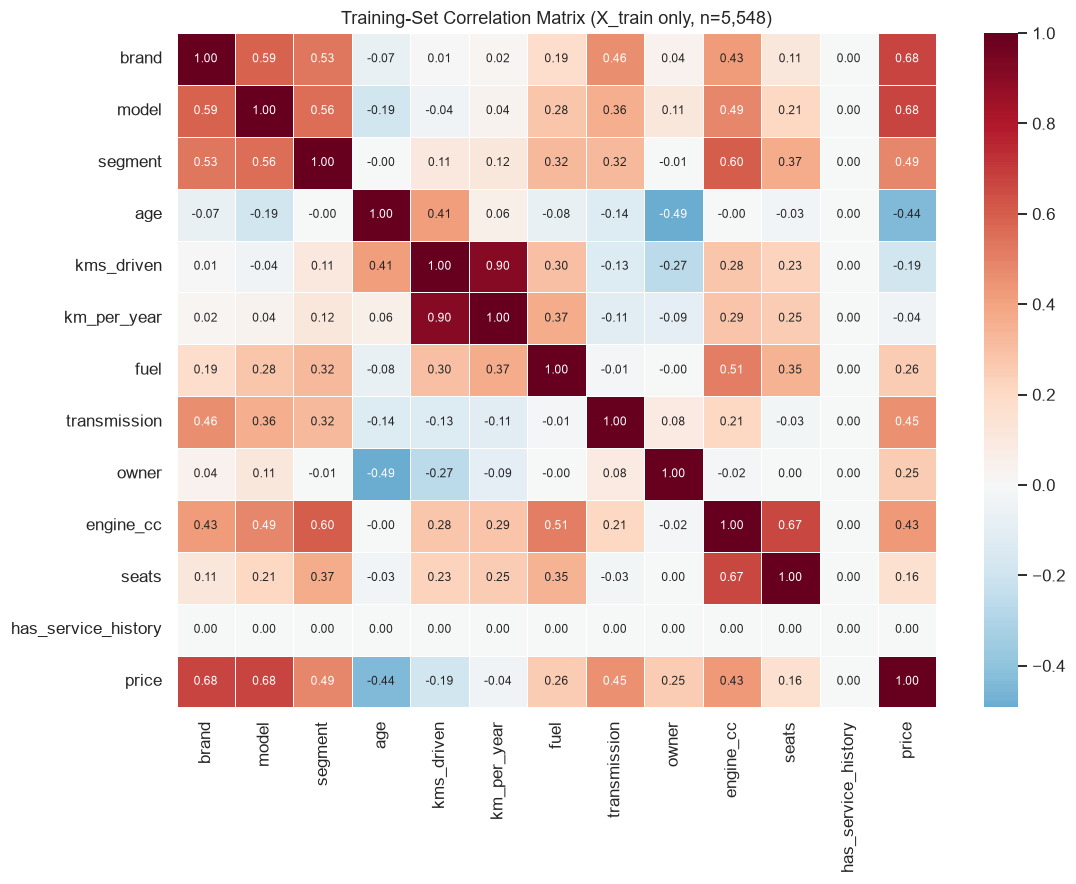

In [8]:
from sklearn.model_selection import train_test_split

X_all = feat[ALL_CANDIDATE_FEATURES].copy()
y_all = feat["price"].astype(float)
groups_all = feat["model"]

X_train_all, X_test_all, y_train, y_test, g_train, g_test = train_test_split(
    X_all, y_all, groups_all, test_size=0.2, random_state=RANDOM_STATE, shuffle=True
)
print(f"Train split: {len(X_train_all):,} rows | Untouched Test holdout: {len(X_test_all):,} rows")

corr_matrix, ranked_corr = compute_training_correlations(X_train_all, y_train)
print("\nFeatures ranked lowest -> highest |Pearson r| with Selling Price (X_train only):")
print(ranked_corr.to_frame("corr_with_price").assign(abs_r=lambda d: d["corr_with_price"].abs()).to_string())

fig, ax = plt.subplots(figsize=(10.5, 8.2))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0.0,
            linewidths=0.5, annot_kws={"size": 8}, ax=ax)
ax.set_title("Training-Set Correlation Matrix (X_train only, n=5,548)")
plt.tight_layout()
plt.show()

Iterative Feature Reduction Log:
 iteration     dropped_feature  n_features    cv_r2  cv_mse_lakh2  group_cv_r2  test_r2
         0                None          12 0.845938      4.250802     0.770694 0.918172
         1 has_service_history          11 0.846161      4.244646     0.770783 0.918326
         2         km_per_year          10 0.845432      4.263546     0.769438 0.918408
         3               seats           9 0.844456      4.273468     0.762683 0.911356
         4          kms_driven           8 0.837696      4.457368     0.762370 0.900476
         5               owner           7 0.835486      4.526873     0.760422 0.893348
         6                fuel           6 0.835838      4.493109     0.750972 0.891671
         7           engine_cc           5 0.800996      5.381538     0.671023 0.858643
         8                 age           4 0.491439     13.501988     0.279431 0.537739
         9        transmission           3 0.456070     14.441096     0.233468 0.502000

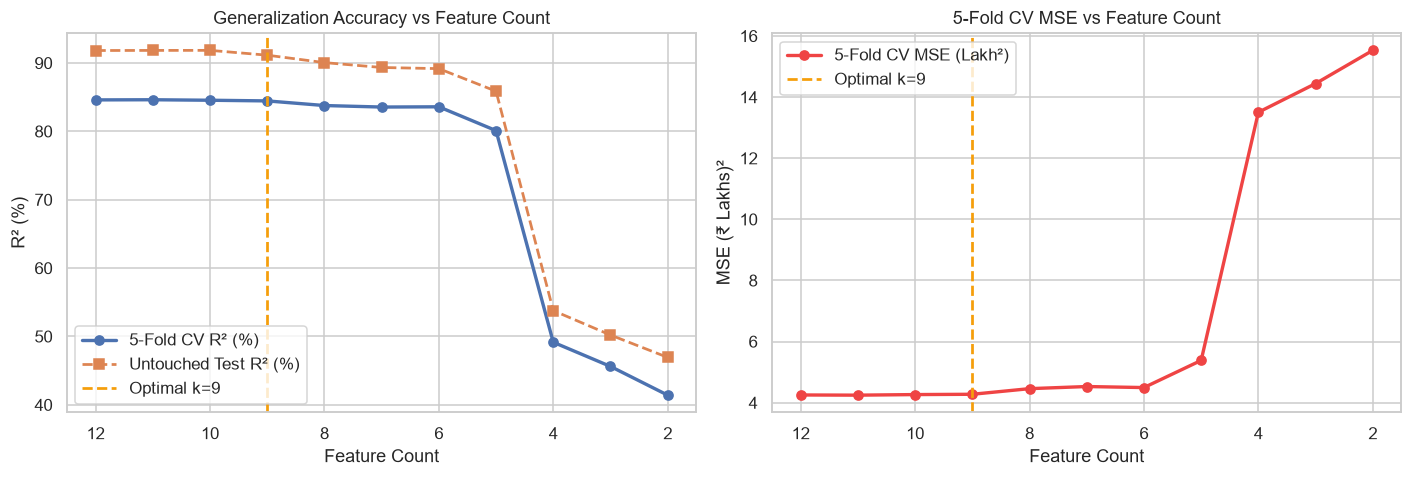


Optimal Reduced Features (9): ['brand', 'model', 'segment', 'age', 'kms_driven', 'fuel', 'transmission', 'owner', 'engine_cc']
Dropped Low-Correlation Features: ['has_service_history', 'km_per_year', 'seats']


In [9]:
# Iterative Feature Reduction + Retraining Loop (dropping lowest |r| feature each round)
reduction_df, selected_9, _, _ = iterative_feature_reduction(
    X_train_all, y_train, X_test_all, y_test, g_train, cv_splits=5
)
print("Iterative Feature Reduction Log:")
print(reduction_df[["iteration", "dropped_feature", "n_features", "cv_r2", "cv_mse_lakh2", "group_cv_r2", "test_r2"]].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(reduction_df["n_features"], reduction_df["cv_r2"] * 100, marker="o", lw=2.2, label="5-Fold CV R² (%)")
ax1.plot(reduction_df["n_features"], reduction_df["test_r2"] * 100, marker="s", lw=1.8, linestyle="--", label="Untouched Test R² (%)")
ax1.axvline(9, color="#f59e0b", linestyle="--", lw=1.8, label="Optimal k=9")
ax1.invert_xaxis()
ax1.set(xlabel="Feature Count", ylabel="R² (%)", title="Generalization Accuracy vs Feature Count")
ax1.legend()

ax2.plot(reduction_df["n_features"], reduction_df["cv_mse_lakh2"], marker="o", color="#ef4444", lw=2.2, label="5-Fold CV MSE (Lakh²)")
ax2.axvline(9, color="#f59e0b", linestyle="--", lw=1.8, label="Optimal k=9")
ax2.invert_xaxis()
ax2.set(xlabel="Feature Count", ylabel="MSE (₹ Lakhs)²", title="5-Fold CV MSE vs Feature Count")
ax2.legend()
plt.tight_layout()
plt.show()

print(f"\nOptimal Reduced Features ({len(selected_9)}): {selected_9}")
print(f"Dropped Low-Correlation Features: {DROPPED_LOW_CORR_FEATURES}")

## 6. Leak-Free `Pipeline` + 5-Fold `GridSearchCV` Hyperparameter Tuning

All preprocessing (`OneHotEncoder`, `SimpleImputer`, `StandardScaler`, and `SVR`'s `TransformedTargetRegressor(log1p/expm1)`) is wrapped inside `sklearn.pipeline.Pipeline` so every CV fold fits preprocessing strictly on its training partition.

Models evaluated via `GridSearchCV(cv=5, n_jobs=-1)` on `X_train[MARKET_FEATURES]`:
- **SVM (`SVR`)**: `kernel` (`linear`, `rbf`), `C` (`0.1`, `1`, `10`), `gamma` (`scale`, `auto`)
- **Random Forest (`RandomForestRegressor`)**: `n_estimators` (`10`, `100`, `500`), `max_depth` (`None`, `3`, `5`, `10`), `min_samples_split` (`2`, `5`, `10`), `max_features` (`sqrt`, `1.0`)
- **KNN (`KNeighborsRegressor`)**: `n_neighbors` (`3`, `5`, `7`, `9`), `weights` (`uniform`, `distance`), `metric` (`euclidean`, `manhattan`)

In [10]:
# Run full leak-free tuning workflow (skipping redundant reduction loop since we ran it above)
market_model, market_meta, (X_test, y_test, pred), comp_df = tune_market(
    feat, models=("svr", "random_forest", "knn"), run_reduction_audit=False, verbose=True
)

print("\n=== FINAL MODEL SELECTION LEADERBOARD (Ranked by 5-Fold CV R²) ===")
display_lb = comp_df[["model", "cv_r2", "cv_mse_lakh2", "group_cv_r2", "test_r2", "test_mse_lakh2", "test_mae", "test_mape", "best_params"]].copy()
display_lb["cv_r2"] = (display_lb["cv_r2"] * 100).map("{:.2f}%".format)
display_lb["group_cv_r2"] = (display_lb["group_cv_r2"] * 100).map("{:.2f}%".format)
display_lb["test_r2"] = (display_lb["test_r2"] * 100).map("{:.2f}%".format)
display_lb["test_mape"] = (display_lb["test_mape"] * 100).map("{:.2f}%".format)
display_lb["test_mae"] = display_lb["test_mae"].map("Rs {:,.0f}".format)
print(display_lb.to_string(index=False))


5-Fold GridSearchCV on 9 reduced features (5,548 train / 1,387 untouched test)...


  svr             Train R2: 0.8758 | 5-Fold CV R2: 0.8445 | CV MSE: 4.273 L2 | GroupCV R2: 0.7627 | Test R2: 0.9114 | Test MAE: Rs 84,283 (35.9s)
    best_params: {'C': 10.0, 'gamma': 'auto', 'kernel': 'rbf'}


  random_forest   Train R2: 0.9783 | 5-Fold CV R2: 0.8312 | CV MSE: 4.605 L2 | GroupCV R2: 0.7200 | Test R2: 0.9231 | Test MAE: Rs 84,599 (115.4s)
    best_params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 500}


  knn             Train R2: 0.9991 | 5-Fold CV R2: 0.8285 | CV MSE: 4.606 L2 | GroupCV R2: 0.6450 | Test R2: 0.8953 | Test MAE: Rs 92,213 (16.4s)
    best_params: {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'distance'}

Winner: svr (5-Fold CV R2 = 0.8445, Untouched Test R2 = 0.9114)

=== FINAL MODEL SELECTION LEADERBOARD (Ranked by 5-Fold CV R²) ===
        model  cv_r2  cv_mse_lakh2 group_cv_r2 test_r2  test_mse_lakh2  test_mae test_mape                                                                              best_params
          svr 84.45%      4.273468      76.27%  91.14%        2.927569 Rs 84,283    16.27%                                            {'C': 10.0, 'gamma': 'auto', 'kernel': 'rbf'}
random_forest 83.12%      4.605206      72.00%  92.31%        2.539255 Rs 84,599    18.52% {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 500}
          knn 82.85%      4.605926      64.50%  89.53%        3.458456 Rs 92,213    19.22%         

Before (12 Features, Unoptimized Baselines):
  old_hist_gb_12         Train= 88.93% | CV_R2= 79.53% | Test_R2= 86.44% | MAE=Rs 99,465
  default_svr_raw_12     Train= -4.71% | CV_R2= -4.78% | Test_R2= -7.03% | MAE=Rs 306,038
  default_svr_log_12     Train= 88.37% | CV_R2= 83.98% | Test_R2= 90.94% | MAE=Rs 87,348
  default_rf_12          Train= 97.44% | CV_R2= 81.01% | Test_R2= 89.71% | MAE=Rs 88,173
  default_knn_12         Train= 86.55% | CV_R2= 78.49% | Test_R2= 87.12% | MAE=Rs 98,271


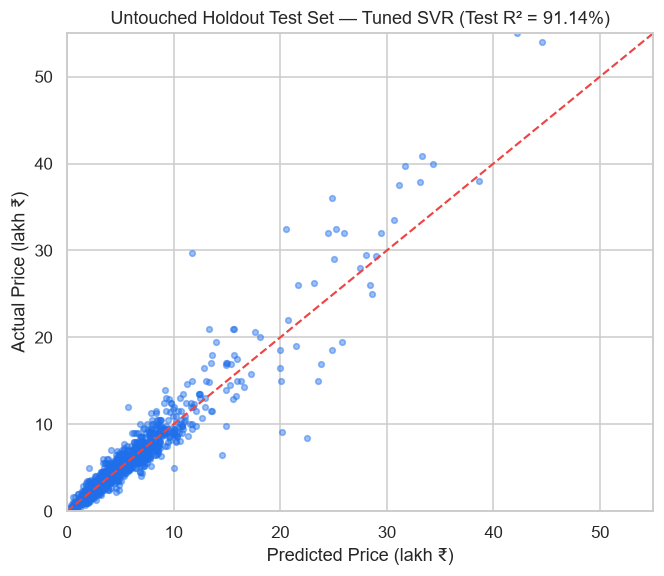

In [11]:
# Before (12-feature baselines) vs After (9-feature tuned models)
b12 = market_meta["optimization"]["baselines_12_features"]
print("Before (12 Features, Unoptimized Baselines):")
for name, m in b12.items():
    print(f"  {name:<22} Train={m['train_r2']*100:6.2f}% | CV_R2={m['cv_r2']*100:6.2f}% | Test_R2={m['test_r2']*100:6.2f}% | MAE=Rs {m['test_mae']:,.0f}")

# Actual vs Predicted scatter on untouched test set
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.scatter(pred / LAKH, y_test / LAKH, s=14, alpha=0.45, color="#1f6feb")
lim = [0, 55]
ax.plot(lim, lim, "--", color="#ef4444", lw=1.4)
ax.set(xlim=lim, ylim=lim, xlabel="Predicted Price (lakh ₹)", ylabel="Actual Price (lakh ₹)",
       title=f"Untouched Holdout Test Set — Tuned {market_meta['market_model'].upper()} (Test R² = {market_meta['test_metrics']['test_r2']*100:.2f}%)")
plt.tight_layout()
plt.show()

## 7. GroupKFold Leakage Audit (Unseen Car Models)

In [12]:
from sklearn.model_selection import GroupKFold, KFold, cross_validate

X9 = feat[MARKET_FEATURES]
y9 = feat["price"].astype(float)
best_svr = build_market_pipeline("svr", kernel="rbf", C=10.0, gamma="auto")

naive_s = cross_validate(best_svr, X9, y9, cv=KFold(5, shuffle=True, random_state=42), scoring="r2", n_jobs=-1)["test_score"]
group_s = cross_validate(best_svr, X9, y9, cv=GroupKFold(5), groups=feat["model"], scoring="r2", n_jobs=-1)["test_score"]

print(f"Random 5-Fold KFold R² : {naive_s.mean():.4f} +/- {naive_s.std():.4f}")
print(f"Model-Grouped CV    R² : {group_s.mean():.4f} +/- {group_s.std():.4f}")
print(f"Optimism gap caught    : {naive_s.mean() - group_s.mean():+.4f}")

Random 5-Fold KFold R² : 0.8730 +/- 0.0565
Model-Grouped CV    R² : 0.7598 +/- 0.0667
Optimism gap caught    : +0.1132


## 8. End-to-End Hybrid Valuations & 2026 Spot-Checks

In [13]:
valuator = CarValuator(market_model, market_meta)

CASES = [
    ("2019 Maruti Swift, 50k km, 2nd owner", dict(brand="Maruti Suzuki", model="Swift", year=2019, kms_driven=50_057, owner="Second Owner")),
    ("2023 Maruti Swift, 20k km", dict(brand="Maruti Suzuki", model="Swift", year=2023, kms_driven=20_000)),
    ("2021 Hyundai Creta, 42k km", dict(brand="Hyundai", model="Creta", year=2021, kms_driven=42_000)),
    ("2020 Maruti Baleno, Automatic", dict(brand="Maruti Suzuki", model="Baleno", year=2020, kms_driven=38_000, transmission="Automatic")),
    ("2025 Kia Syros (Unseen)", dict(brand="Kia", model="Syros", year=2025, kms_driven=6_000)),
    ("2026 Kia Clavis (Unreleased)", dict(brand="Kia", model="Clavis", year=2026, kms_driven=3_000)),
    ("2025 Maruti eVitara (EV)", dict(brand="Maruti Suzuki", model="eVitara", year=2025, kms_driven=8_000, fuel="Electric")),
    ("2024 Tesla Model Y (Unseen Brand)", dict(brand="Tesla", model="Model Y", year=2024, kms_driven=15_000, fuel="Electric")),
]

rows = []
for label, kw in CASES:
    v = valuator.value(CarQuery(**kw))
    rows.append({"car": label, "estimate_Rs": round(v.price), "low_Rs": round(v.low),
                 "high_Rs": round(v.high), "segment": v.segment, "confidence": v.confidence, "known": v.known_model})
print(pd.DataFrame(rows).to_string(index=False))

TRUTH = [
    ("2019 Swift, 50k, 2nd owner", "Maruti Suzuki", "Swift", 2019, 50_057, "Second Owner", 467_000),
    ("2023 Swift, 20k",            "Maruti Suzuki", "Swift", 2023, 20_000, "First Owner",  624_000),
    ("2022 Swift, 30k",            "Maruti Suzuki", "Swift", 2022, 30_000, "First Owner",  593_000),
    ("2017 Swift, 60k",            "Maruti Suzuki", "Swift", 2017, 60_000, "First Owner",  385_000),
]
t_rows = []
for lbl, b, m, yr, km, ow, act in TRUTH:
    v = valuator.value(CarQuery(brand=b, model=m, year=yr, kms_driven=km, owner=ow))
    t_rows.append({"car": lbl, "estimate": round(v.price), "actual_2026": act,
                   "error_%": round(100 * (v.price - act) / act, 1)})
print("\n2026 Spot-Checks:")
print(pd.DataFrame(t_rows).to_string(index=False))

                                 car  estimate_Rs  low_Rs  high_Rs   segment confidence  known
2019 Maruti Swift, 50k km, 2nd owner       508807  452838   564776 hatchback       high   True
           2023 Maruti Swift, 20k km       694933  618491   771376 hatchback       high   True
          2021 Hyundai Creta, 42k km      1096725  976085  1217364       suv       high   True
       2020 Maruti Baleno, Automatic       669865  596180   743551 hatchback       high   True
             2025 Kia Syros (Unseen)       882566  723704  1041427       suv     medium  False
        2026 Kia Clavis (Unreleased)       889724  729573  1049874       suv     medium  False
            2025 Maruti eVitara (EV)      1584647 1299410  1869883    ev-suv     medium  False
   2024 Tesla Model Y (Unseen Brand)      5073411 4160197  5986626    ev-suv     medium  False

2026 Spot-Checks:
                       car  estimate  actual_2026  error_%
2019 Swift, 50k, 2nd owner    508807       467000      9.0
        

## 9. Aligned 7-Input Web Query Demo & Artifact Export

In [14]:
# Aligned 7 user inputs (+ auto-resolved segment & engine_cc = 9 ML features)
form = {
    "brand": "Maruti Suzuki",
    "model": "Baleno",
    "year": 2020,
    "kms_driven": 38_000,
    "fuel": "Petrol",
    "transmission": "Automatic",
    "owner": "First Owner",
}
v = valuator.value(CarQuery(**form))
print(f"2020 Baleno Auto -> Rs {v.price:,.0f} (Range: Rs {v.low:,.0f} - Rs {v.high:,.0f}, {v.confidence} confidence)")

2020 Baleno Auto -> Rs 669,865 (Range: Rs 596,180 - Rs 743,551, high confidence)
